In [ ]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

#File path
folder = Path("/content/drive/MyDrive/data_files_csv")

# Exclude previously generated merged files
excluded_files = ["merged_common_hospitals.csv", "merged_year_common_hospitals.csv", "merged_year_common_hospitals_new.csv", "Merged_CY_Extracts_2004_2024"]
files = sorted([f for f in folder.glob("*.csv") if f.name not in excluded_files])

#columns to be extracted -> included the ones highlghted in the excel sheet
keep_cols = [
    "FAC_NO",
    "FAC_NAME",
    "BEG_DATE",
    "END_DATE",
    "DAY_PER",
    "DATA_IND",
    "AUDIT_IND",
    "COUNTY",
    "HSA",
    "HFPA",
    "TYPE_CNTRL",
    "TYPE_CARE",
    "TYPE_HOSP",
    "TEACH_RURL",
    "PHONE",
    "ADDRESS",
    "CITY",
    "ZIP_CODE",
    "CEO",
    "CEO_TITLE",
    "WEB_SITE",
    "OWNER",
    "DAY_TOT",
    "DIS_TOT",
    "DIS_NURSRY",
    "VIS_TOT",
    "VIS_ER",
    "VIS_CLIN",
    "VIS_REF_OP",
    "OP_MIN_IP",
    "OP_MIN_OP",
    "SURG_IP",
    "SURG_OP",
    "NAT_0BIRTHS",
    "C_SECTIONS",
    "EXP_DLY",
    "EXP_AMB",
    "EXP_ANC",
    "EXP_PIP",
    "EXP_POP",
    "EXP_RES",
    "EXP_ED",
    "EXP_GEN",
    "EXP_FISC",
    "EXP_ADM",
    "EXP_UNASSG",
    "EXP_SAL",
    "EXP_BEN",
    "EXP_PHYS",
    "EXP_OTHPRO",
    "EXP_SUPP",
    "EXP_PURCH",
    "EXP_DEPRE",
    "EXP_LEASES",
    "EXP_INSUR",
    "EXP_INTRST",
    "EXP_OTH",
    "HOSP_FTE",
    "NURS_FTE",
    "PROD_HRS",
    "NON_PRD_HR",
    "PAID_HRS",
    "MED_STAFF",
    "STDNT_FTE",
    "PRD_HR_DLY",
    "PRD_HR_AMB",
    "PRD_HR_ANC",
    "PRD_HR_ED",
    "PRD_HR_GEN",
    "PRD_HR_FIS",
    "PRD_HR_ADM",
    "PRD_HR_NON",
    "PD_HR_DLY",
    "PD_HR_AMB",
    "PD_HR_ANC",
    "PD_HR_ED",
    "PD_HR_GEN",
    "PD_HR_FIS",
    "PD_HR_ADM",
    "PD_HR_NON"
]

# store each cleaned dataframe
dfs = []
# store hospital ID sets from each file
hospital_sets = []

for f in files:
    df = pd.read_csv(f)

    # keep only columns that exist
    cols = [c for c in keep_cols if c in df.columns]
    df = df[cols].copy()

    # make sure hospital_id is consistent
    df["FAC_NO"] = df["FAC_NO"].astype(str).str.strip()

    dfs.append(df)
    hospital_sets.append(set(df["FAC_NO"].dropna().unique()))

# hospitals present in every file
common_hospitals = set.intersection(*hospital_sets)

# filter each dataframe to only those hospitals
filtered_dfs = [
    df[df["FAC_NO"].isin(common_hospitals)].copy()
    for df in dfs
]

# combine into one dataset
merged = pd.concat(filtered_dfs, ignore_index=True)

#merged.to_csv(folder / "merged_common_hospitals.csv", index=False)

print("Hospitals in every file:", len(common_hospitals))
print("Rows in merged file:", len(merged))

Hospitals in every file: 357
Rows in merged file: 10810


In [ ]:
merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10810 entries, 0 to 10809
Data columns (total 80 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   FAC_NO       10810 non-null  object 
 1   FAC_NAME     10810 non-null  object 
 2   BEG_DATE     7220 non-null   object 
 3   END_DATE     7220 non-null   object 
 4   DAY_PER      7220 non-null   float64
 5   DATA_IND     7220 non-null   object 
 6   AUDIT_IND    7220 non-null   object 
 7   COUNTY       7204 non-null   object 
 8   HSA          7220 non-null   float64
 9   HFPA         7220 non-null   float64
 10  TYPE_CNTRL   7220 non-null   object 
 11  TYPE_CARE    7220 non-null   object 
 12  TYPE_HOSP    7220 non-null   object 
 13  TEACH_RURL   1616 non-null   object 
 14  PHONE        7220 non-null   object 
 15  ADDRESS      7220 non-null   object 
 16  CITY         7220 non-null   object 
 17  ZIP_CODE     7220 non-null   object 
 18  CEO          7220 non-null   object 
 19  CEO_

In [ ]:
print("Null values in the merged dataset:")
display(merged.isnull().sum())

Null values in the merged dataset:


,0
FAC_NO,0
FAC_NAME,0
BEG_DATE,3590
END_DATE,3590
DAY_PER,3590
...,...
PD_HR_GEN,3590
PD_HR_FIS,3590
PD_HR_ADM,3590
PD_HR_NON,5026


In [ ]:
'''
unique_hospitals = merged['FAC_NAME'].unique()
print(unique_hospitals)
'''

"\nunique_hospitals = merged['FAC_NAME'].unique()\nprint(unique_hospitals)\n"

In [ ]:
merged.to_csv(folder / "merged_common_hospitals.csv", index=False)
print(f"Merged data saved to: {folder / 'merged_common_hospitals.csv'}")

Merged data saved to: /content/drive/MyDrive/data_files_csv/merged_common_hospitals.csv


In [ ]:
'''Plot overhead expenses vs patient expenses over time'''

# Define patient expense columns
patient_expense_cols = [
    'EXP_DLY',
    'EXP_AMB',
    'EXP_ANC',
    'EXP_PIP',
    'EXP_POP'
]

# Define overhead expense columns
overhead_expense_cols = [
    'EXP_RES',
    'EXP_ED',
    'EXP_GEN',
    'EXP_FISC',
    'EXP_ADM',
    'EXP_UNASSG'
]


In [ ]:
# Ensure 'BEG_DATE' is in datetime format, handling mixed formats and coercing errors
merged['BEG_DATE'] = pd.to_datetime(merged['BEG_DATE'], format='mixed', errors='coerce')

# Extract the year from 'BEG_DATE'
merged['BEG_YEAR'] = merged['BEG_DATE'].dt.year

# Group by 'BEG_YEAR' and count unique hospitals ('FAC_NO')
hospitals_by_beg_year = merged.groupby('BEG_YEAR')['FAC_NO'].nunique().reset_index()
hospitals_by_beg_year = hospitals_by_beg_year.rename(columns={'FAC_NO': 'Number_of_Hospitals'})

print("Sum of hospitals by beginning year:")
display(hospitals_by_beg_year)

Sum of hospitals by beginning year:


,BEG_YEAR,Number_of_Hospitals
0,2003.0,189
1,2004.0,169
2,2008.0,186
3,2009.0,171
4,2013.0,180
5,2014.0,180
6,2018.0,180
7,2019.0,180
8,2023.0,178
9,2024.0,179


Some Notes: Even though the data is for CY, the report still is collected in terms of fiscal year, so when I plot the data with BEG_Date as the reference variable it shows some hospitals to be 2023/2003 etc

In [ ]:
merged_with_end_year = merged.copy()

# Ensure 'END_DATE' is in datetime format, handling mixed formats and coercing errors
merged_with_end_year['END_DATE'] = pd.to_datetime(merged_with_end_year['END_DATE'], format='mixed', errors='coerce')

# Assign 'YEAR' based on 'END_DATE'
merged_with_end_year['YEAR'] = merged_with_end_year['END_DATE'].dt.year

print("New DataFrame 'merged_with_end_year' created with 'YEAR' column based on END_DATE.")
display(merged_with_end_year.head())

New DataFrame 'merged_with_end_year' created with 'YEAR' column based on END_DATE.


,FAC_NO,FAC_NAME,BEG_DATE,END_DATE,DAY_PER,DATA_IND,AUDIT_IND,COUNTY,HSA,HFPA,...,PD_HR_AMB,PD_HR_ANC,PD_HR_ED,PD_HR_GEN,PD_HR_FIS,PD_HR_ADM,PD_HR_NON,NAT_0BIRTHS,BEG_YEAR,YEAR
0,106010846,ALAMEDA COUNTY MEDICAL CENTER,2003-07-01,2004-06-30,366.0,AUDITED,EXCL. IND. AUDIT,ALAMEDA,5.0,417.0,...,786518.0,619394.0,282217.0,892239.0,407129.0,482813.0,NaN,NaN,2003.0,2004.0
1,106010735,ALAMEDA HOSPITAL,2003-07-01,2004-06-30,366.0,AUDITED,INCL. IND. AUDIT,ALAMEDA,5.0,417.0,...,43688.0,203882.0,0.0,152714.0,72787.0,107765.0,NaN,NaN,2003.0,2004.0
2,106190017,ALHAMBRA HOSPITAL - ALHAMBRA,2003-07-01,2004-06-30,366.0,AUDITED,EXCL. IND. AUDIT,LOS ANGELES,11.0,913.0,...,33666.0,200830.0,0.0,123190.0,65041.0,101170.0,NaN,NaN,2003.0,2004.0
3,106010739,ALTA BATES SUMMIT MED CTR-ALTA BATES CAM,2004-01-01,2004-12-31,366.0,AUDITED,INCL. IND. AUDIT,ALAMEDA,5.0,415.0,...,227360.0,1203534.0,6377.0,805001.0,172990.0,388515.0,NaN,NaN,2004.0,2004.0
4,106010937,ALTA BATES SUMMIT MED CTR-SUMMIT-HAWTHOR,2004-01-01,2004-12-31,366.0,AUDITED,INCL. IND. AUDIT,ALAMEDA,5.0,417.0,...,158076.0,906146.0,340026.0,690224.0,176223.0,231959.0,NaN,NaN,2004.0,2004.0


In [ ]:
merged_with_end_year.to_csv(folder / "merged_year_common_hospitals.csv", index=False)
print(f"Merged data saved to: {folder / 'merged_year_common_hospitals.csv'}")

Merged data saved to: /content/drive/MyDrive/data_files_csv/merged_year_common_hospitals.csv


In [ ]:
# Define patient expense columns
patient_expense_cols = [
    'EXP_DLY',
    'EXP_AMB',
    'EXP_ANC',
    'EXP_PIP',
    'EXP_POP'
]

# Define overhead expense columns
overhead_expense_cols = [
    'EXP_RES',
    'EXP_ED',
    'EXP_GEN',
    'EXP_FISC',
    'EXP_ADM',
    'EXP_UNASSG'
]

# Calculate total patient expenses for each record in merged_with_end_year
merged_with_end_year['Patient_Expenses'] = merged_with_end_year[patient_expense_cols].sum(axis=1)

# Calculate total overhead expenses for each record in merged_with_end_year
merged_with_end_year['Overhead_Expenses'] = merged_with_end_year[overhead_expense_cols].sum(axis=1)

# Group by YEAR (derived from END_DATE) and sum patient and overhead expenses
yearly_expenses_end_date = merged_with_end_year.groupby('YEAR')[['Patient_Expenses', 'Overhead_Expenses']].sum().reset_index()

# Calculate the total combined expenses for patient and overhead
yearly_expenses_end_date['Total_Combined_Expenses'] = yearly_expenses_end_date['Patient_Expenses'] + yearly_expenses_end_date['Overhead_Expenses']

# Calculate the percentage of Patient Expenses
yearly_expenses_end_date['Patient_Expense_Percentage'] = (yearly_expenses_end_date['Patient_Expenses'] / yearly_expenses_end_date['Total_Combined_Expenses']) * 100

# Calculate the percentage of Overhead Expenses
yearly_expenses_end_date['Overhead_Expense_Percentage'] = (yearly_expenses_end_date['Overhead_Expenses'] / yearly_expenses_end_date['Total_Combined_Expenses']) * 100

display(yearly_expenses_end_date[['YEAR', 'Patient_Expense_Percentage', 'Overhead_Expense_Percentage']])

,YEAR,Patient_Expense_Percentage,Overhead_Expense_Percentage
0,2004.0,60.890059,39.109941
1,2009.0,61.561269,38.438731
2,2014.0,59.017496,40.982504
3,2019.0,59.423566,40.576434
4,2024.0,59.983245,40.016755


In [ ]:
print("\nSum of Patient and Overhead Expenses and Total Expenses by Year:")
display(yearly_expenses_end_date[['YEAR', 'Patient_Expenses', 'Overhead_Expenses','Total_Combined_Expenses']])


Sum of Patient and Overhead Expenses and Total Expenses by Year:


,YEAR,Patient_Expenses,Overhead_Expenses,Total_Combined_Expenses
0,2004.0,1.112453e+11,7.145330e+10,1.826986e+11
1,2009.0,1.667982e+11,1.041484e+11,2.709466e+11
2,2014.0,2.016225e+11,1.400092e+11,3.416317e+11
3,2019.0,2.830667e+11,1.932876e+11,4.763542e+11
4,2024.0,3.899017e+11,2.601160e+11,6.500177e+11


/tmp/ipykernel_27760/769256935.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='YEAR', y='Total_Combined_Expenses', data=yearly_expenses_end_date, palette='viridis')


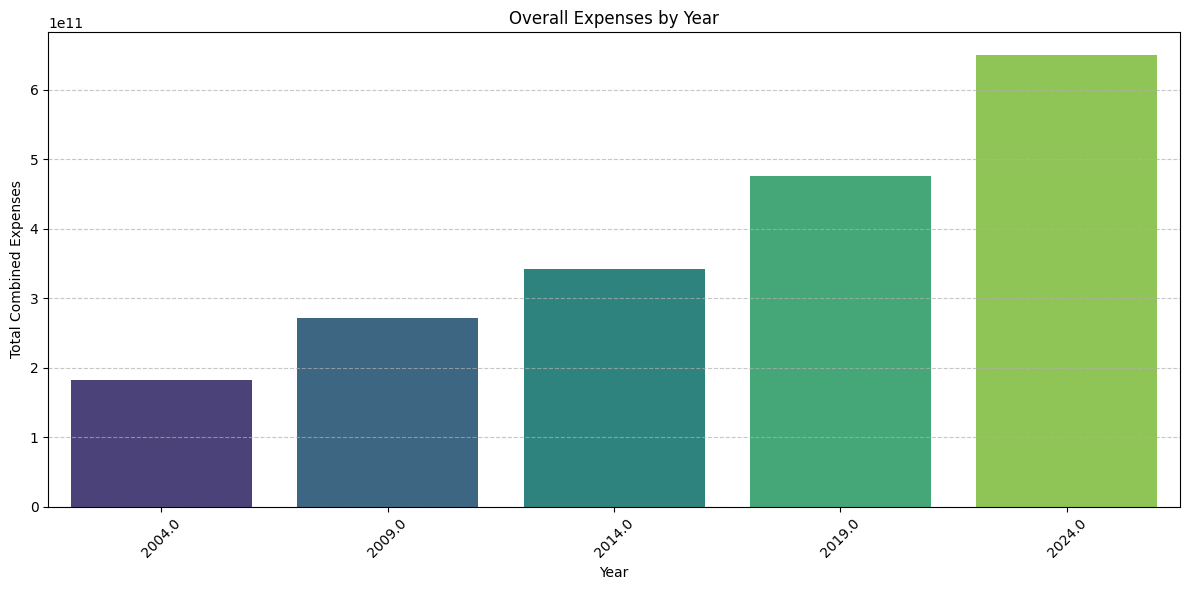

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(x='YEAR', y='Total_Combined_Expenses', data=yearly_expenses_end_date, palette='viridis')
plt.title('Overall Expenses by Year')
plt.xlabel('Year')
plt.ylabel('Total Combined Expenses')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Breakdown of Patient Expenses by Type Over Time

This chart visualizes how different types of patient expenses (`EXP_DLY`, `EXP_AMB`, `EXP_ANC`, `EXP_PIP`, `EXP_POP`) contribute to the total patient expenses each year. Each colored segment represents a specific expense category, stacked to show their combined impact over time.

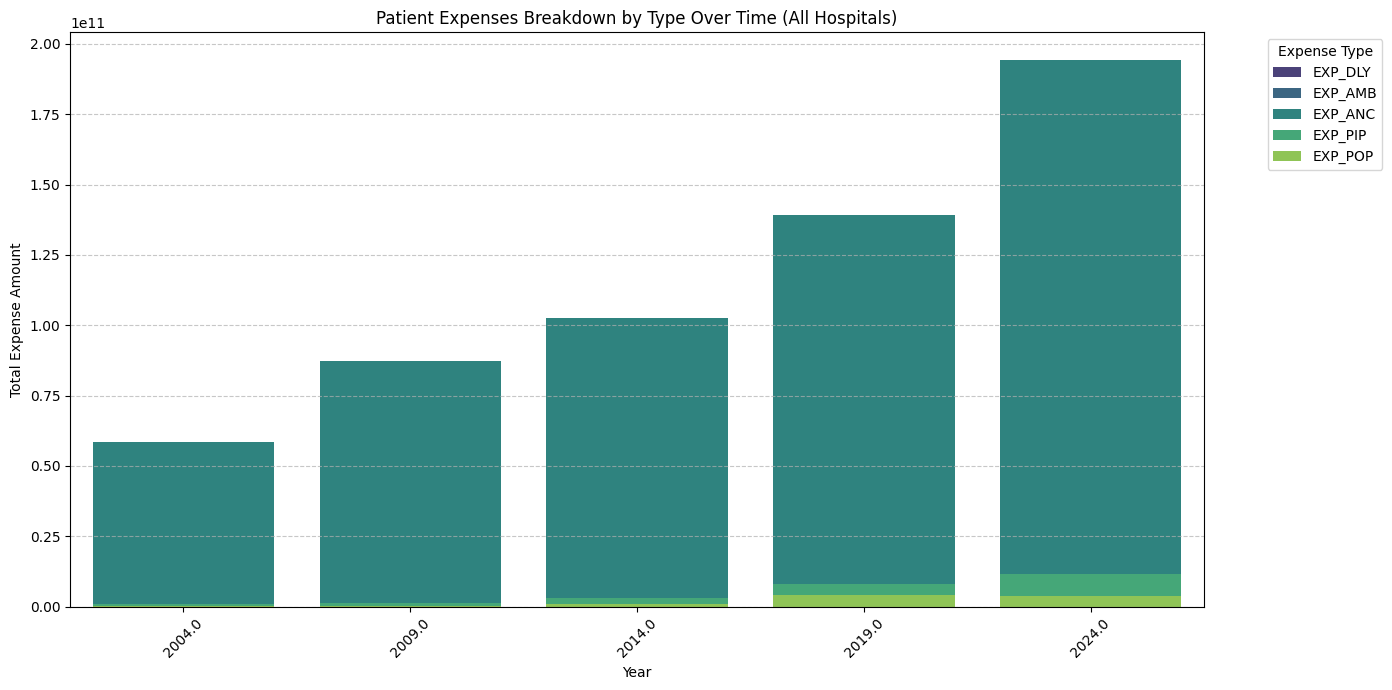

In [ ]:
# Prepare data for patient expense breakdown
patient_expenses_breakdown = merged_with_end_year[['YEAR'] + patient_expense_cols].groupby('YEAR')[patient_expense_cols].sum().reset_index()
patient_expenses_melted = patient_expenses_breakdown.melt(id_vars=['YEAR'], var_name='Expense_Type', value_name='Amount')

# Set the figure size
plt.figure(figsize=(14, 7))

# Create a stacked bar chart for patient expense breakdown
sns.barplot(x='YEAR', y='Amount', hue='Expense_Type', data=patient_expenses_melted, palette='viridis', dodge=False)

plt.title('Patient Expenses Breakdown by Type Over Time (All Hospitals)')
plt.xlabel('Year')
plt.ylabel('Total Expense Amount')
plt.legend(title='Expense Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Breakdown of Overhead Expenses by Type Over Time

This chart illustrates the contribution of various overhead expense types (`EXP_RES`, `EXP_ED`, `EXP_GEN`, `EXP_FISC`, `EXP_ADM`, `EXP_UNASSG`) to the total overhead expenses each year. Similar to the patient expenses, each segment represents a distinct overhead category, providing insight into their yearly trends and combined totals.

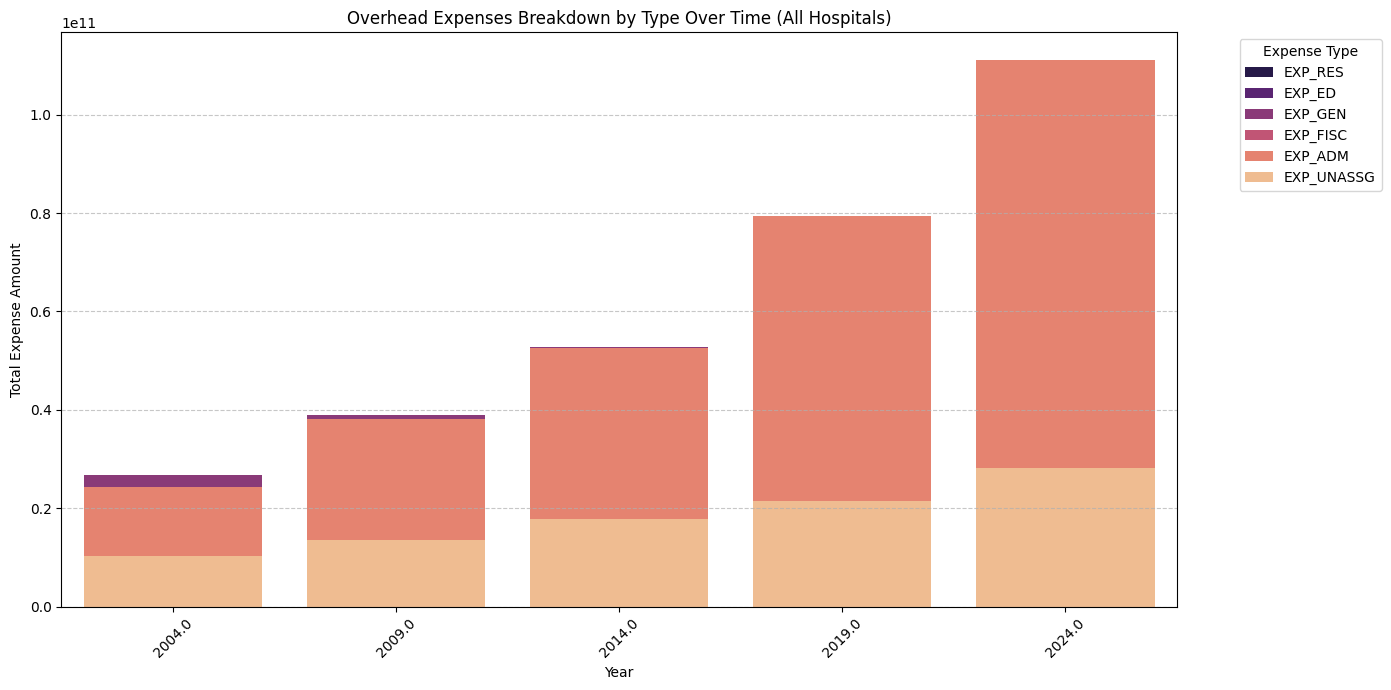

In [ ]:
# Prepare data for overhead expense breakdown
overhead_expenses_breakdown = merged_with_end_year[['YEAR'] + overhead_expense_cols].groupby('YEAR')[overhead_expense_cols].sum().reset_index()
overhead_expenses_melted = overhead_expenses_breakdown.melt(id_vars=['YEAR'], var_name='Expense_Type', value_name='Amount')

# Set the figure size
plt.figure(figsize=(14, 7))

# Create a stacked bar chart for overhead expense breakdown
sns.barplot(x='YEAR', y='Amount', hue='Expense_Type', data=overhead_expenses_melted, palette='magma', dodge=False)

plt.title('Overhead Expenses Breakdown by Type Over Time (All Hospitals)')
plt.xlabel('Year')
plt.ylabel('Total Expense Amount')
plt.legend(title='Expense Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Combined Breakdown of All Patient and Overhead Expenses Over Time

This chart visualizes the trends of all patient and overhead expenses over time. Each segment represents a specific expense category, allowing for a comprehensive comparison of these critical cost components.

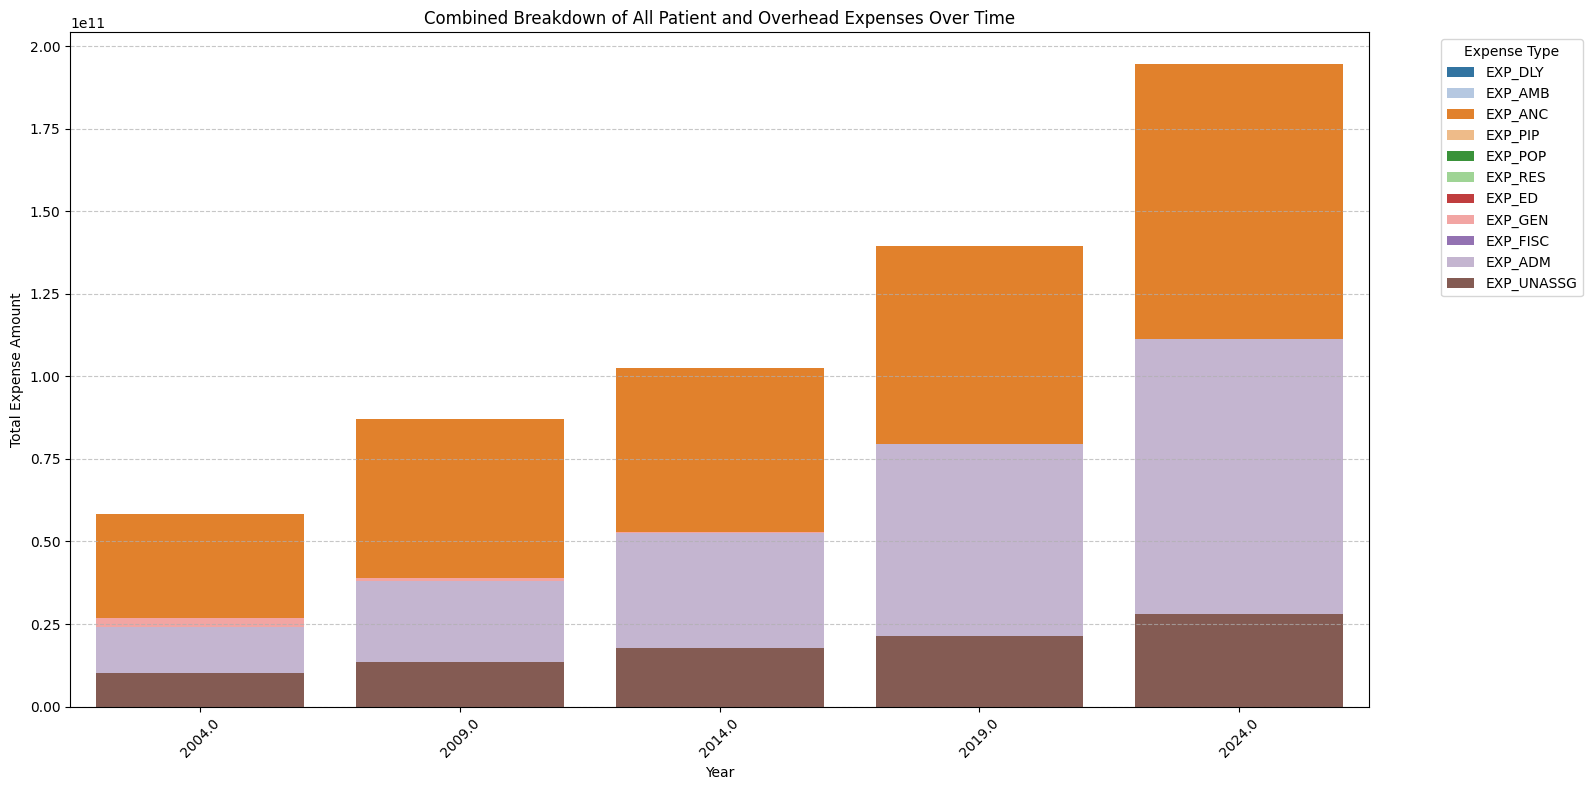

In [ ]:
# Combine all expense columns
all_expense_cols = patient_expense_cols + overhead_expense_cols

# Prepare data for the combined breakdown
all_expenses_breakdown = merged_with_end_year[['YEAR'] + all_expense_cols].groupby('YEAR')[all_expense_cols].sum().reset_index()
all_expenses_melted = all_expenses_breakdown.melt(id_vars=['YEAR'], var_name='Expense_Type', value_name='Amount')

# Set the figure size
plt.figure(figsize=(16, 8))

# Create a stacked bar chart for the combined expense breakdown
sns.barplot(x='YEAR', y='Amount', hue='Expense_Type', data=all_expenses_melted, palette='tab20', dodge=False)

plt.title('Combined Breakdown of All Patient and Overhead Expenses Over Time')
plt.xlabel('Year')
plt.ylabel('Total Expense Amount')
plt.legend(title='Expense Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

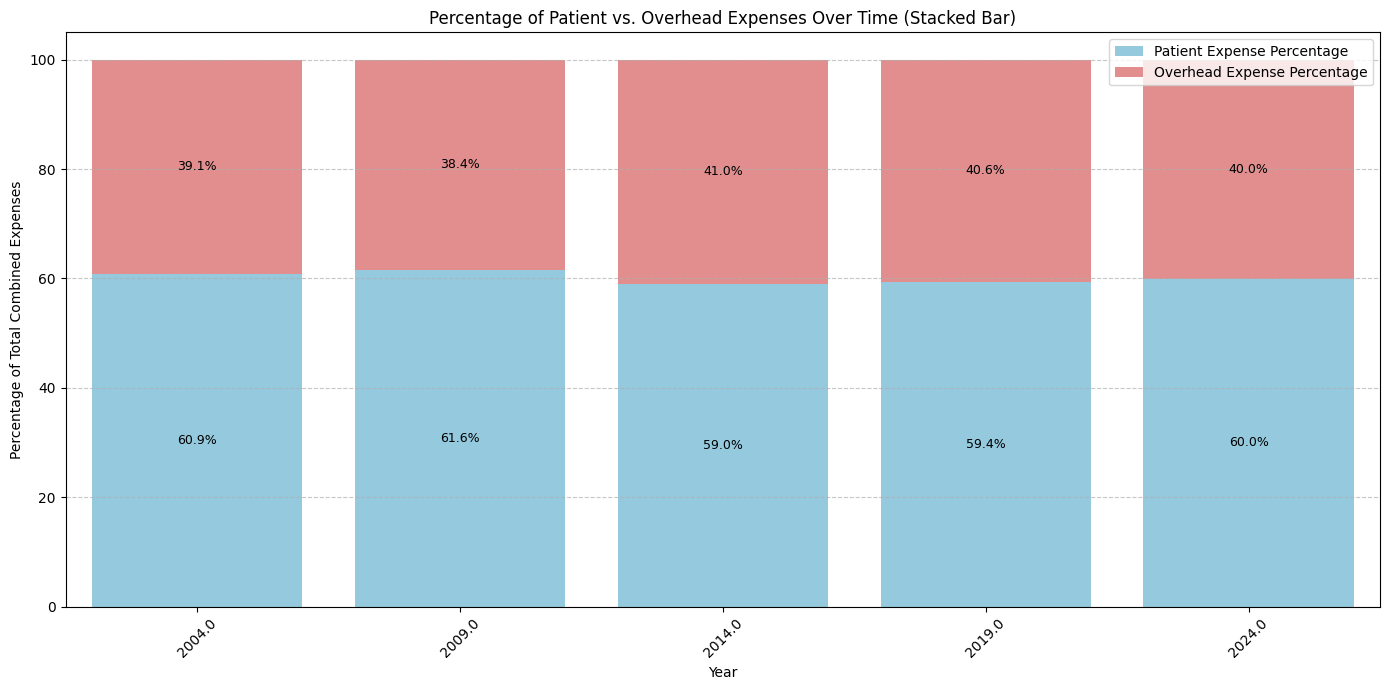

In [ ]:
# Prepare data for stacked bar plot (already available in yearly_expenses_end_date)
# The dataframe yearly_expenses_end_date has 'YEAR', 'Patient_Expense_Percentage', 'Overhead_Expense_Percentage'

# Set the figure size
plt.figure(figsize=(14, 7))

# Plot Patient Expense Percentage
sns.barplot(x='YEAR', y='Patient_Expense_Percentage', data=yearly_expenses_end_date, color='skyblue', label='Patient Expense Percentage')

# Plot Overhead Expense Percentage on top of Patient Expense Percentage
plot = sns.barplot(x='YEAR', y='Overhead_Expense_Percentage', data=yearly_expenses_end_date, color='lightcoral', bottom=yearly_expenses_end_date['Patient_Expense_Percentage'], label='Overhead Expense Percentage')

# Add percentage labels
for bar in plot.patches:
    # Get the x, y, width, and height of the bar
    x = bar.get_x() + bar.get_width() / 2
    y = bar.get_y() + bar.get_height() / 2
    height = bar.get_height()

    if height > 0: # Only add label if the bar has height
        # Add the text label
        plt.text(x, y, f'{height:.1f}%', ha='center', va='center', color='black', fontsize=9)

plt.title('Percentage of Patient vs. Overhead Expenses Over Time (Stacked Bar)')
plt.xlabel('Year')
plt.ylabel('Percentage of Total Combined Expenses')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45) # Rotate x-axis labels if they overlap
plt.tight_layout()
plt.show()

In [ ]:
#converting data to lower case as there is a mix of both
merged_with_end_year['TYPE_HOSP'] = merged_with_end_year['TYPE_HOSP'].str.lower()
merged_with_end_year['TYPE_CARE'] = merged_with_end_year['TYPE_CARE'].str.lower()

print("Hospital type counts:")
display(merged_with_end_year['TYPE_HOSP'].value_counts())

print("Care type counts:")
display(merged_with_end_year['TYPE_CARE'].value_counts())

Hospital type counts:


,count
TYPE_HOSP,
comparable,6308
kaiser,452
phf,260
state,100
ltc emphasis,60
other non-comparable,40


Care type counts:


,count
TYPE_CARE,
general,5824
psychiatric,744
specialty,440
children,124
childrens,88


In [ ]:
#creating subset of comparable hospitals
comparable_hospitals_df = merged_with_end_year[merged_with_end_year['TYPE_HOSP'] == 'comparable'].copy()

In [ ]:
# Calculate total patient and overhead expenses for the comparable hospitals subset
yearly_expenses_comparable = comparable_hospitals_df.groupby('YEAR')[['Patient_Expenses', 'Overhead_Expenses']].sum().reset_index()

# Calculate the total combined expenses
yearly_expenses_comparable['Total_Combined_Expenses'] = yearly_expenses_comparable['Patient_Expenses'] + yearly_expenses_comparable['Overhead_Expenses']

# Calculate the percentage of Patient Expenses
yearly_expenses_comparable['Patient_Expense_Percentage'] = (yearly_expenses_comparable['Patient_Expenses'] / yearly_expenses_comparable['Total_Combined_Expenses']) * 100

# Calculate the percentage of Overhead Expenses
yearly_expenses_comparable['Overhead_Expense_Percentage'] = (yearly_expenses_comparable['Overhead_Expenses'] / yearly_expenses_comparable['Total_Combined_Expenses']) * 100

display(yearly_expenses_comparable[['YEAR', 'Patient_Expense_Percentage', 'Overhead_Expense_Percentage']])

,YEAR,Patient_Expense_Percentage,Overhead_Expense_Percentage
0,2004.0,61.966452,38.033548
1,2009.0,62.147807,37.852193
2,2014.0,58.279412,41.720588
3,2019.0,58.893337,41.106663
4,2024.0,59.788634,40.211366


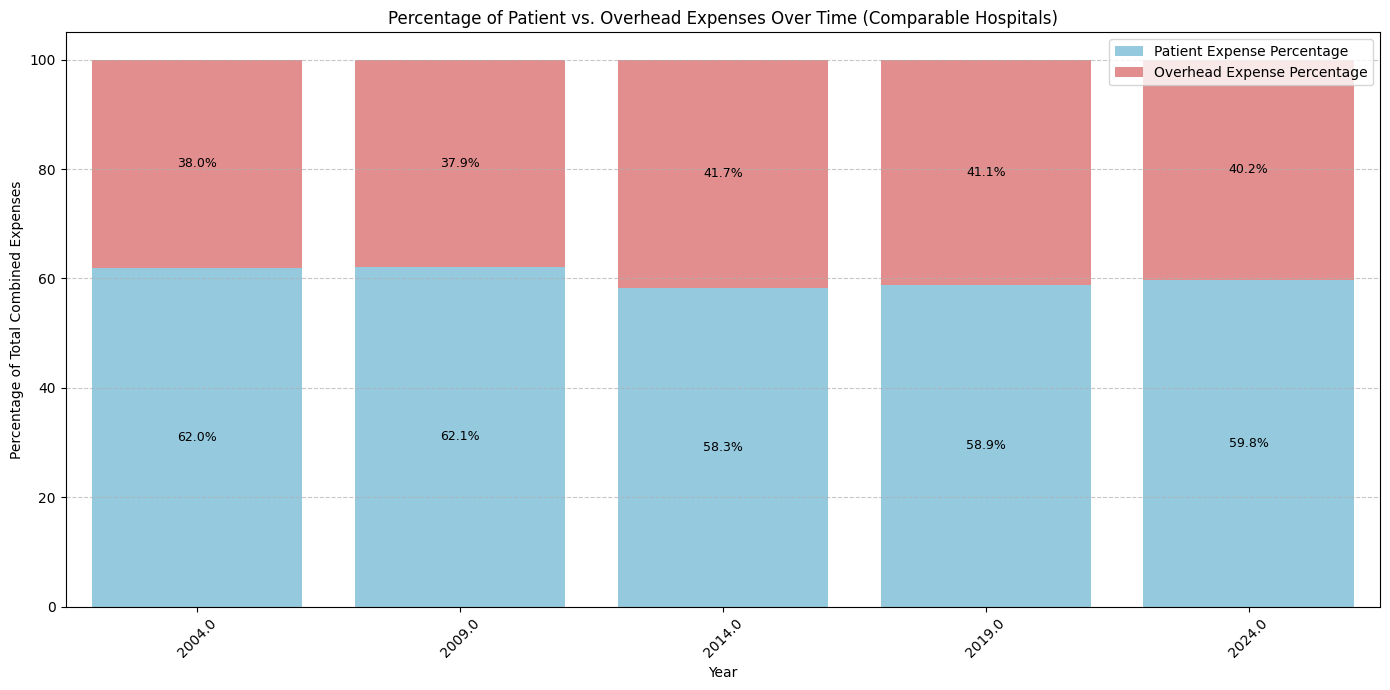

In [ ]:
# Prepare data for stacked bar plot (already available in yearly_expenses_comparable)

# Set the figure size
plt.figure(figsize=(14, 7))

# Plot Patient Expense Percentage
plot = sns.barplot(x='YEAR', y='Patient_Expense_Percentage', data=yearly_expenses_comparable, color='skyblue', label='Patient Expense Percentage')

# Plot Overhead Expense Percentage on top of Patient Expense Percentage
sns.barplot(x='YEAR', y='Overhead_Expense_Percentage', data=yearly_expenses_comparable, color='lightcoral', bottom=yearly_expenses_comparable['Patient_Expense_Percentage'], label='Overhead Expense Percentage')

# Add percentage labels
for bar in plot.patches:
    # Get the x, y, width, and height of the bar
    x = bar.get_x() + bar.get_width() / 2
    y = bar.get_y() + bar.get_height() / 2
    height = bar.get_height()

    if height > 0: # Only add label if the bar has height
        # Add the text label
        plt.text(x, y, f'{height:.1f}%', ha='center', va='center', color='black', fontsize=9)

plt.title('Percentage of Patient vs. Overhead Expenses Over Time (Comparable Hospitals)')
plt.xlabel('Year')
plt.ylabel('Percentage of Total Combined Expenses')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45) # Rotate x-axis labels if they overlap
plt.tight_layout()
plt.show()

In [ ]:
'''
checking for multiple entries in same year
'''
# Group by 'FAC_NO' and 'YEAR' and count the occurrences
duplicate_entries = merged_with_end_year.groupby(['FAC_NO', 'YEAR']).size().reset_index(name='record_count')

# Filter for entries where the count is greater than 1 (indicating duplicates for that hospital in that year)
duplicate_hospitals_per_year = duplicate_entries[duplicate_entries['record_count'] > 1]

# Display the results
if not duplicate_hospitals_per_year.empty:
    print("Hospitals with multiple entries in the same year:")
    display(duplicate_hospitals_per_year.sort_values(by=['FAC_NO', 'YEAR']).head(20))
else:
    print("No hospitals have multiple entries in the same year based on FAC_NO and YEAR.")

Hospitals with multiple entries in the same year:


,FAC_NO,YEAR,record_count
0,106010735,2004.0,4
1,106010735,2009.0,4
2,106010735,2014.0,8
3,106010735,2019.0,4
4,106010735,2024.0,4
5,106010739,2004.0,4
6,106010739,2009.0,4
7,106010739,2014.0,4
8,106010739,2019.0,4
9,106010739,2024.0,4


In [ ]:
display(yearly_expenses_end_date[['YEAR', 'Patient_Expense_Percentage', 'Overhead_Expense_Percentage']])

,YEAR,Patient_Expense_Percentage,Overhead_Expense_Percentage
0,2004.0,60.890059,39.109941
1,2009.0,61.561269,38.438731
2,2014.0,59.017496,40.982504
3,2019.0,59.423566,40.576434
4,2024.0,59.983245,40.016755


In [ ]:
display(yearly_expenses_comparable[['YEAR', 'Patient_Expense_Percentage', 'Overhead_Expense_Percentage']])

,YEAR,Patient_Expense_Percentage,Overhead_Expense_Percentage
0,2004.0,61.966452,38.033548
1,2009.0,62.147807,37.852193
2,2014.0,58.279412,41.720588
3,2019.0,58.893337,41.106663
4,2024.0,59.788634,40.211366


##3/26

In [ ]:
merged_with_end_year['Total_Combined_Expenses'] = merged_with_end_year['Patient_Expenses'] + merged_with_end_year['Overhead_Expenses']
# Based on the user's new definition:
# Total FTE = HOSP_FTE
# Other FTE = HOSP_FTE - (NURS_FTE + STDNT_FTE)

merged_with_end_year['Other_FTE'] = merged_with_end_year['HOSP_FTE'] - (merged_with_end_year['NURS_FTE'] + merged_with_end_year['STDNT_FTE'])


print("DataFrame with 'Total_FTE' and 'Other_FTE' columns added:")
display(merged_with_end_year[['FAC_NO', 'YEAR', 'HOSP_FTE', 'NURS_FTE', 'STDNT_FTE', 'Other_FTE']].head())

DataFrame with 'Total_FTE' and 'Other_FTE' columns added:


,FAC_NO,YEAR,HOSP_FTE,NURS_FTE,STDNT_FTE,Other_FTE
0,106010846,2004.0,2168.0,572.0,102.0,1494.0
1,106010735,2004.0,382.0,118.0,0.0,264.0
2,106190017,2004.0,429.0,178.0,0.0,251.0
3,106010739,2004.0,2062.0,690.0,0.0,1372.0
4,106010937,2004.0,1599.0,555.0,2.0,1042.0


In [ ]:
'''Cost per Hour'''
# Ensure Patient_Expenses and Overhead_Expenses are calculated at the row level
# These columns were already calculated in cell 6c220b34, but we'll ensure they exist for this step
if 'Patient_Expenses' not in merged_with_end_year.columns:
    merged_with_end_year['Patient_Expenses'] = merged_with_end_year[patient_expense_cols].sum(axis=1)
if 'Overhead_Expenses' not in merged_with_end_year.columns:
    merged_with_end_year['Overhead_Expenses'] = merged_with_end_year[overhead_expense_cols].sum(axis=1)

# Update patient and overhead expense columns to include newly added columns if relevant
# For simplicity, assuming new columns might contribute to either patient or overhead if explicitly defined.
# For now, keeping the original definitions unless specified otherwise.
# patient_expense_cols and overhead_expense_cols were defined before.

# Calculate COST_PER_HOUR
# Handle potential division by zero for PAID_HRS
#merged_with_end_year['COST_PER_HOUR'] = merged_with_end_year.apply(lambda row: row['Total_Combined_Expenses'] / row['PAID_HRS'] if row['PAID_HRS'] != 0 else 0, axis=1)

#print("DataFrame with 'Total_Combined_Expenses' and 'COST_PER_HOUR' columns added (first 5 rows):")
#display(merged_with_end_year[['FAC_NO', 'YEAR', 'PAID_HRS', 'Total_Combined_Expenses', 'COST_PER_HOUR']].head())


 Total Operating Expenses by Year:


,YEAR,Patient_Expenses,Overhead_Expenses,Total_Combined_Expenses
0,2004.0,1.112453e+11,7.145330e+10,1.826986e+11
1,2009.0,1.667982e+11,1.041484e+11,2.709466e+11
2,2014.0,2.016225e+11,1.400092e+11,3.416317e+11
3,2019.0,2.830667e+11,1.932876e+11,4.763542e+11
4,2024.0,3.899017e+11,2.601160e+11,6.500177e+11


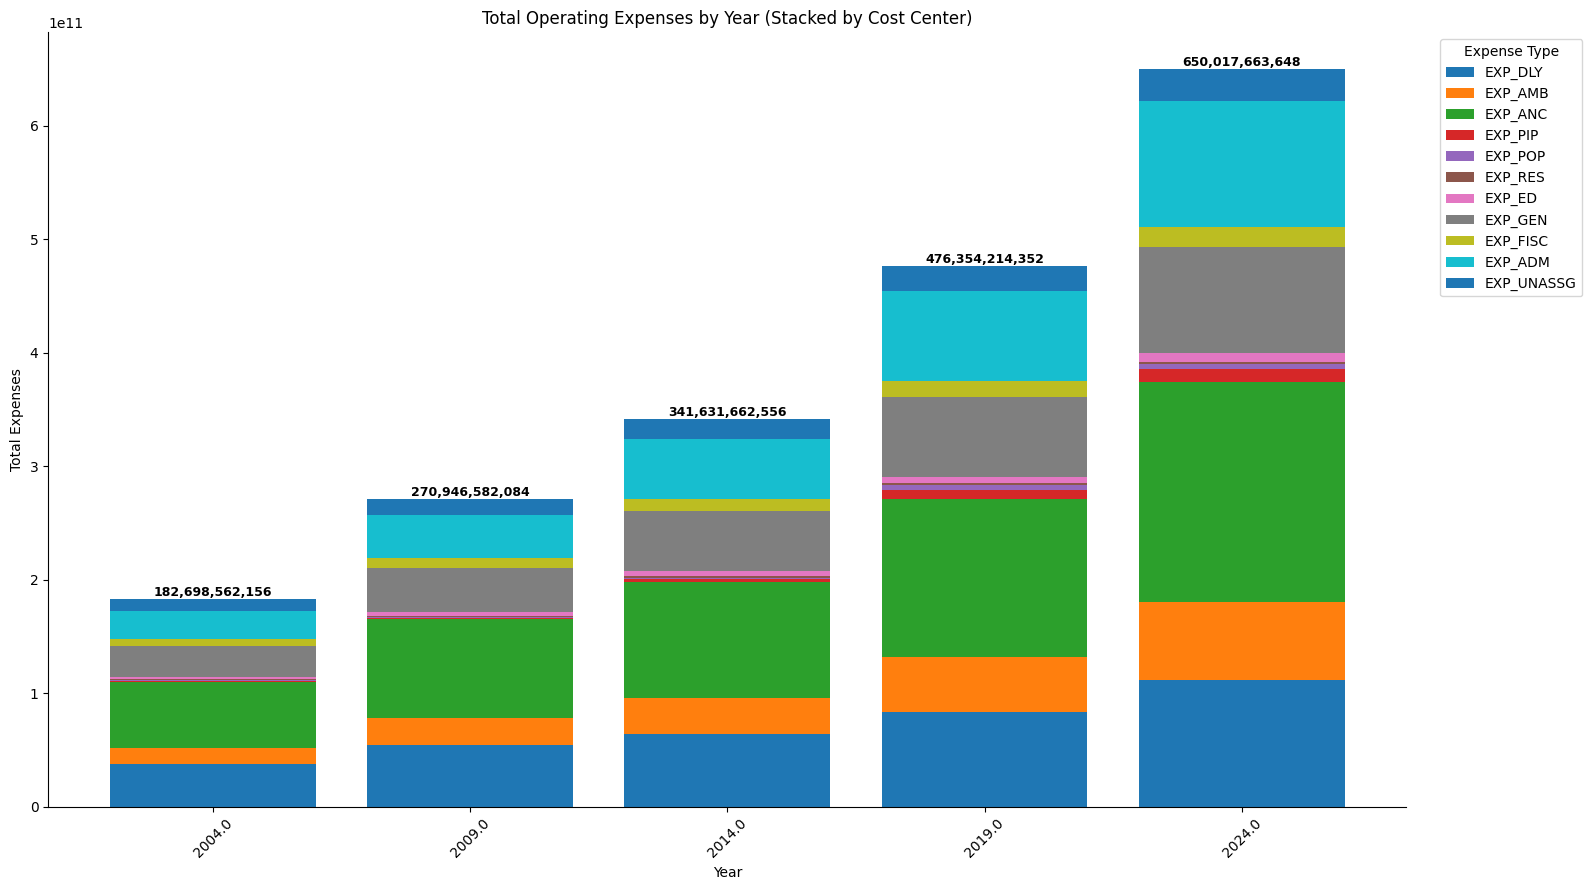

In [ ]:
# Using the predefined all_expense_cols from earlier in the notebook
# all_expense_cols = [
#     "EXP_DLY",    # Daily Hospital Services
#     "EXP_AMB",    # Ambulatory Services
#     "EXP_ANC",    # Ancillary Services
#     "EXP_PIP",    # Purchased Inpatient Services
#     "EXP_POP",    # Purchased Outpatient Services
#     "EXP_RES",    # Research
#     "EXP_ED",     # Education
#     "EXP_GEN",    # General Services
#     "EXP_FISC",   # Fiscal Services
#     "EXP_ADM",    # Administrative Services
#     "EXP_UNASSG"  # Unassigned Costs
# ]

# Keep only valid columns (in case one is missing)
# This step is redundant if all_expense_cols is already correctly defined in the notebook context
# We will use the existing all_expense_cols and filter merged_with_end_year
valid_expense_cols = [c for c in all_expense_cols if c in merged_with_end_year.columns]

# --- 3) Sum expenses by year ---
yearly = (
    merged_with_end_year.groupby("YEAR", as_index=False)[valid_expense_cols]
      .sum()
      .sort_values("YEAR")
)

# Optional: total operating expense per year
yearly["TOTAL_EXP"] = yearly[valid_expense_cols].sum(axis=1)

# --- 4) Plot stacked bar chart ---
fig, ax = plt.subplots(figsize=(16, 9))

bottom = pd.Series([0] * len(yearly), index=yearly.index)

for col in valid_expense_cols:
    ax.bar(yearly["YEAR"].astype(str), yearly[col], bottom=bottom, label=col)
    bottom = bottom + yearly[col]

# --- 5) Add total labels on top of each bar ---
for i, total in enumerate(yearly["TOTAL_EXP"]):
    ax.text(
        i,
        total,
        f"{total:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )
print("\n Total Operating Expenses by Year:")
display(yearly_expenses_end_date[['YEAR', 'Patient_Expenses', 'Overhead_Expenses','Total_Combined_Expenses']])

ax.set_title("Total Operating Expenses by Year (Stacked by Cost Center)")
ax.set_xlabel("Year")
ax.set_ylabel("Total Expenses")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Expense Type")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate Total FTEs for each row
# Assuming Total FTEs is the sum of Hospital FTE, Nursing FTE, and Student FTE
#merged_with_end_year['Total_FTE'] = merged_with_end_year['HOSP_FTE'] + merged_with_end_year['NURS_FTE'] + merged_with_end_year['STDNT_FTE']

# Calculate AVG_WAGE using EXP_SAL and TOTAL_FTE
# Handle potential division by zero for TOTAL_FTE
merged_with_end_year['AVG_WAGE'] = merged_with_end_year.apply(lambda row: row['EXP_SAL'] / row['HOSP_FTE'] if row['HOSP_FTE'] != 0 else 0, axis=1)

print("DataFrame with 'AVG_WAGE' column added (first 5 rows):")
display(merged_with_end_year[['FAC_NO', 'YEAR', 'EXP_SAL', 'HOSP_FTE', 'NURS_FTE', 'STDNT_FTE', 'Other_FTE', 'AVG_WAGE']].head())
yearly_expenses_fte = merged_with_end_year.groupby('YEAR')[['Total_Combined_Expenses', 'HOSP_FTE']].sum().reset_index()
yearly_avg_wage = merged_with_end_year.groupby('YEAR')['AVG_WAGE'].mean().reset_index()

DataFrame with 'AVG_WAGE' column added (first 5 rows):


,FAC_NO,YEAR,EXP_SAL,HOSP_FTE,NURS_FTE,STDNT_FTE,Other_FTE,AVG_WAGE
0,106010846,2004.0,137744075.0,2168.0,572.0,102.0,1494.0,63535.089945
1,106010735,2004.0,21300626.0,382.0,118.0,0.0,264.0,55760.801047
2,106190017,2004.0,18569143.0,429.0,178.0,0.0,251.0,43284.715618
3,106010739,2004.0,134753463.0,2062.0,690.0,0.0,1372.0,65350.854995
4,106010937,2004.0,117317925.0,1599.0,555.0,2.0,1042.0,73369.559099


In [ ]:
merged_with_end_year.head()

,FAC_NO,FAC_NAME,BEG_DATE,END_DATE,DAY_PER,DATA_IND,AUDIT_IND,COUNTY,HSA,HFPA,...,PD_HR_ADM,PD_HR_NON,NAT_0BIRTHS,BEG_YEAR,YEAR,Patient_Expenses,Overhead_Expenses,Total_Combined_Expenses,Other_FTE,AVG_WAGE
0,106010846,ALAMEDA COUNTY MEDICAL CENTER,2003-07-01,2004-06-30,366.0,AUDITED,EXCL. IND. AUDIT,ALAMEDA,5.0,417.0,...,482813.0,NaN,NaN,2003.0,2004.0,163621843.0,160311636.0,323933479.0,1494.0,63535.089945
1,106010735,ALAMEDA HOSPITAL,2003-07-01,2004-06-30,366.0,AUDITED,INCL. IND. AUDIT,ALAMEDA,5.0,417.0,...,107765.0,NaN,NaN,2003.0,2004.0,30851410.0,21390163.0,52241573.0,264.0,55760.801047
2,106190017,ALHAMBRA HOSPITAL - ALHAMBRA,2003-07-01,2004-06-30,366.0,AUDITED,EXCL. IND. AUDIT,LOS ANGELES,11.0,913.0,...,101170.0,NaN,NaN,2003.0,2004.0,31497779.0,18946409.0,50444188.0,251.0,43284.715618
3,106010739,ALTA BATES SUMMIT MED CTR-ALTA BATES CAM,2004-01-01,2004-12-31,366.0,AUDITED,INCL. IND. AUDIT,ALAMEDA,5.0,415.0,...,388515.0,NaN,NaN,2004.0,2004.0,277537023.0,157565571.0,435102594.0,1372.0,65350.854995
4,106010937,ALTA BATES SUMMIT MED CTR-SUMMIT-HAWTHOR,2004-01-01,2004-12-31,366.0,AUDITED,INCL. IND. AUDIT,ALAMEDA,5.0,417.0,...,231959.0,NaN,NaN,2004.0,2004.0,202291344.0,124064482.0,326355826.0,1042.0,73369.559099


In [ ]:
#merged_with_end_year.to_csv(folder / "merged_year_common_hospitals_new.csv", index=False)
#print(f"Merged data saved to: {folder / 'merged_year_common_hospitals_new.csv'}")

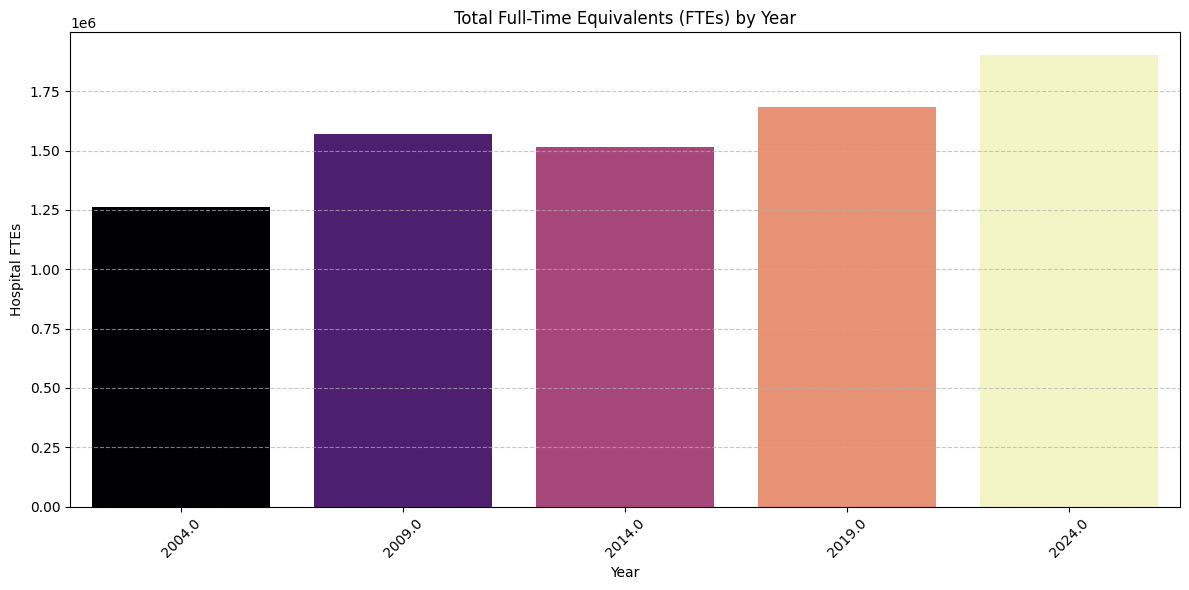

In [ ]:
# Plotting Total_FTEs by Year as a bar chart
plt.figure(figsize=(12, 6))
sns.barplot(x='YEAR', y='HOSP_FTE', data=yearly_expenses_fte, hue='YEAR', palette='magma', legend=False)
plt.title('Total Full-Time Equivalents (FTEs) by Year')
plt.xlabel('Year')
plt.ylabel('Hospital FTEs')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

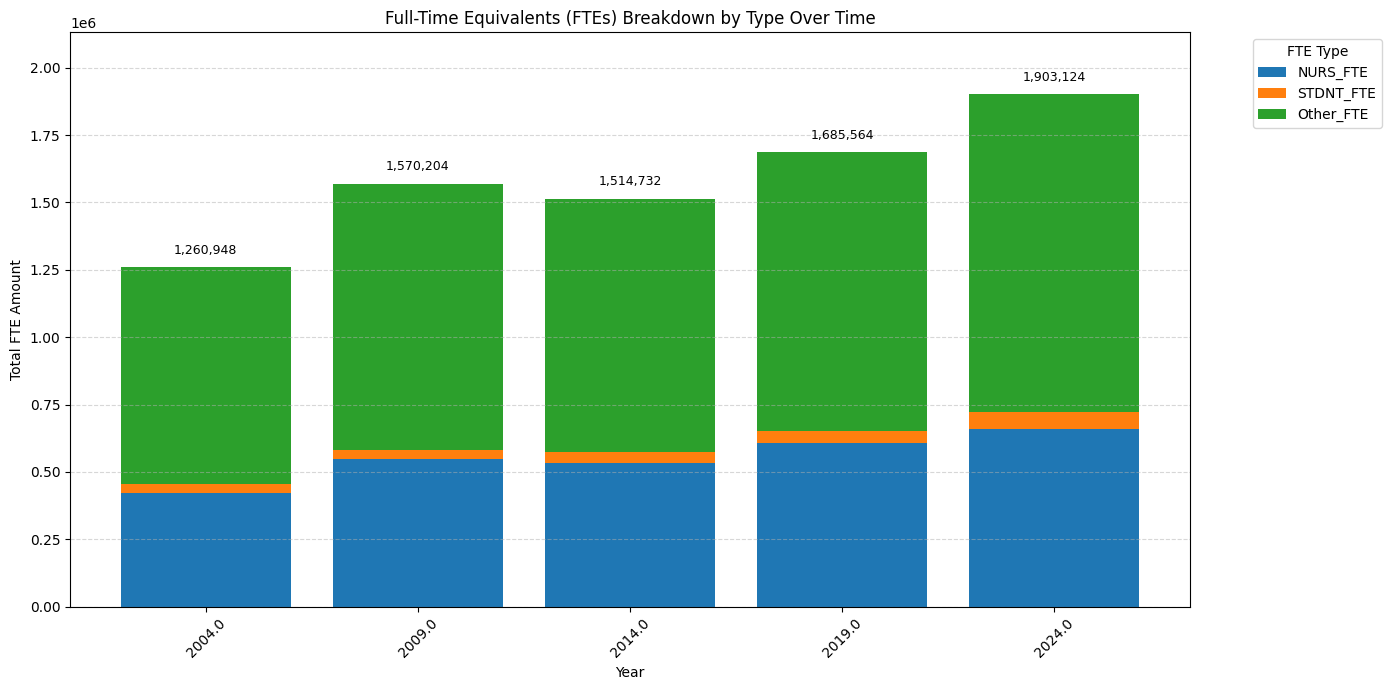

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fte_cols = ['NURS_FTE', 'STDNT_FTE', 'Other_FTE']

# Group by year
fte_breakdown = (
    merged_with_end_year
    .groupby('YEAR')[fte_cols]
    .sum()
    .reset_index()
    .sort_values('YEAR')
)

years = fte_breakdown['YEAR'].astype(str).tolist()
x = np.arange(len(years))

# Use a numpy array for stacking
bottom = np.zeros(len(fte_breakdown))

fig, ax = plt.subplots(figsize=(14, 7))

for col in fte_cols:
    ax.bar(x, fte_breakdown[col].values, bottom=bottom, label=col)
    bottom += fte_breakdown[col].values

# Total labels on top
yearly_total_ftes = fte_breakdown[fte_cols].sum(axis=1).values
offset = yearly_total_ftes.max() * 0.02

for i, total in enumerate(yearly_total_ftes):
    ax.text(
        x[i],
        total + offset,
        f'{total:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9,
        color='black'
    )

ax.set_title('Full-Time Equivalents (FTEs) Breakdown by Type Over Time')
ax.set_xlabel('Year')
ax.set_ylabel('Total FTE Amount')
ax.set_xticks(x)
ax.set_xticklabels(years, rotation=45)
ax.legend(title='FTE Type', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.set_ylim(0, yearly_total_ftes.max() * 1.12)

plt.tight_layout()
plt.show()

Average Wage by Year and Hospital Type:


,YEAR,TYPE_HOSP,AVG_WAGE
0,2004.0,comparable,48716.409360
1,2004.0,kaiser,0.000000
2,2004.0,ltc emphasis,47218.118295
3,2004.0,other non-comparable,0.000000
4,2004.0,phf,16924.869827


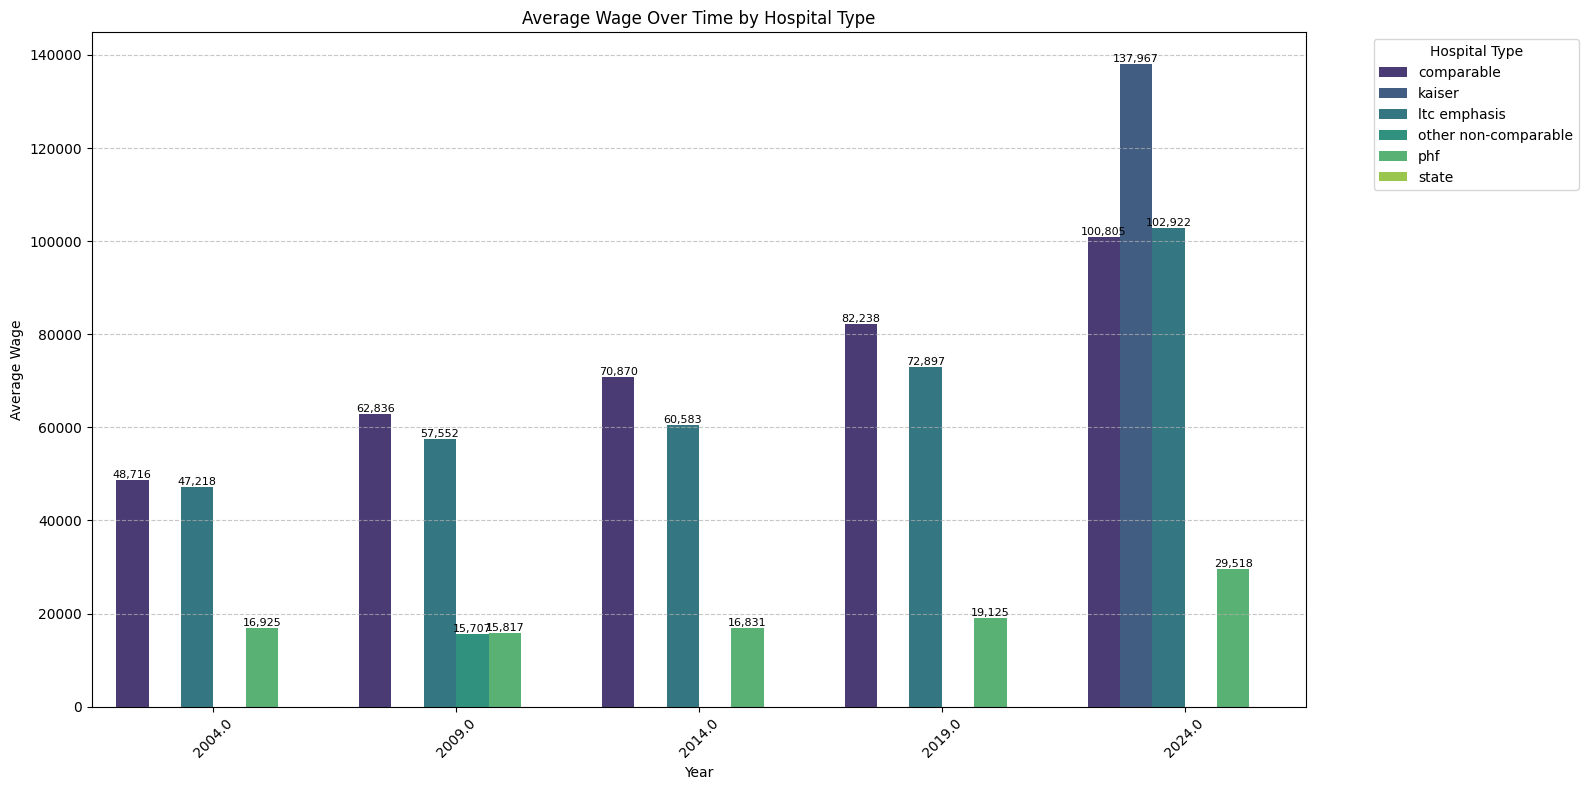

In [ ]:
# Calculate average wage by year and hospital type
yearly_avg_wage_by_type = merged_with_end_year.groupby(['YEAR', 'TYPE_HOSP'])['AVG_WAGE'].mean().reset_index()

print("Average Wage by Year and Hospital Type:")
display(yearly_avg_wage_by_type.head())

# Plot the average wage by year for each hospital type as a grouped bar chart
plt.figure(figsize=(16, 8)) # Increased figure size for better readability
ax = sns.barplot(x='YEAR', y='AVG_WAGE', hue='TYPE_HOSP', data=yearly_avg_wage_by_type, palette='viridis')

plt.title('Average Wage Over Time by Hospital Type')
plt.xlabel('Year')
plt.ylabel('Average Wage')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.legend(title='Hospital Type', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add labels on top of each bar
for container in ax.containers:
    for bar in container:
        height = bar.get_height()
        if height > 0: # Only label non-zero bars
            ax.text(bar.get_x() + bar.get_width() / 2, height, f'{height:,.0f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

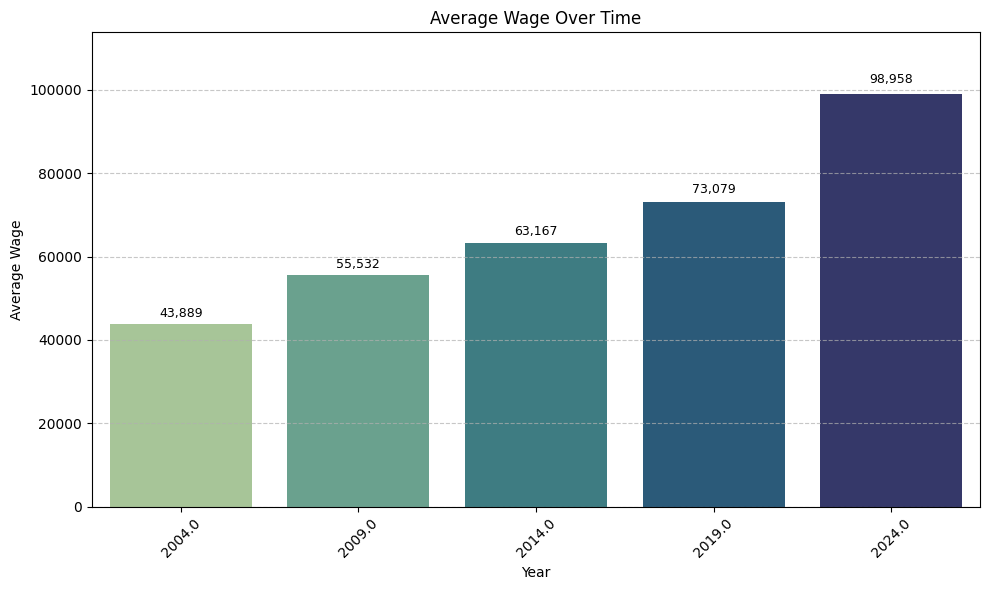

In [ ]:
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x='YEAR',
    y='AVG_WAGE',
    data=yearly_avg_wage,
    palette='crest',
    hue='YEAR',
    legend=False
)

# Add labels
for i, row in yearly_avg_wage.iterrows():
    ax.text(
        i,
        row['AVG_WAGE'] * 1.02,  # small offset above bar
        f"{row['AVG_WAGE']:,.0f}",
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.title('Average Wage Over Time')
plt.xlabel('Year')
plt.ylabel('Average Wage')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)

# add headroom so labels don't get cut off
plt.ylim(0, yearly_avg_wage['AVG_WAGE'].max() * 1.15)

plt.tight_layout()
plt.show()

Yearly Expenses, FTEs, and Expenses per FTE:


,YEAR,Total_Combined_Expenses,HOSP_FTE,Expenses_per_FTE
0,2004.0,1.826986e+11,1260948.0,144889.846493
1,2009.0,2.709466e+11,1570204.0,172555.019656
2,2014.0,3.416317e+11,1514732.0,225539.344621
3,2019.0,4.763542e+11,1685564.0,282608.203754
4,2024.0,6.500177e+11,1903124.0,341552.974818


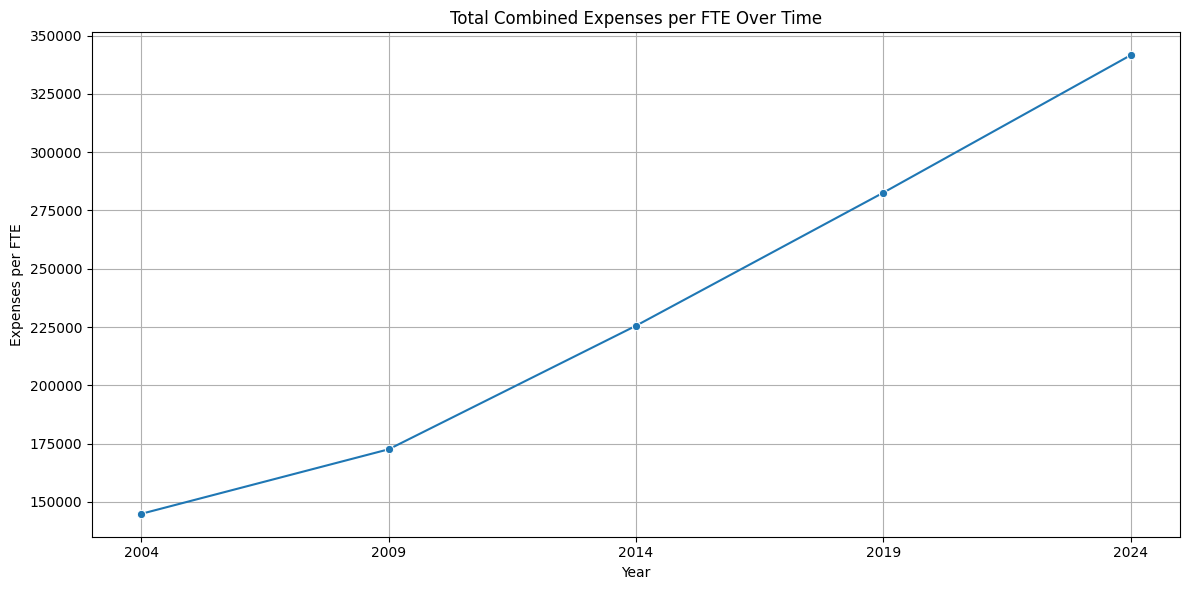

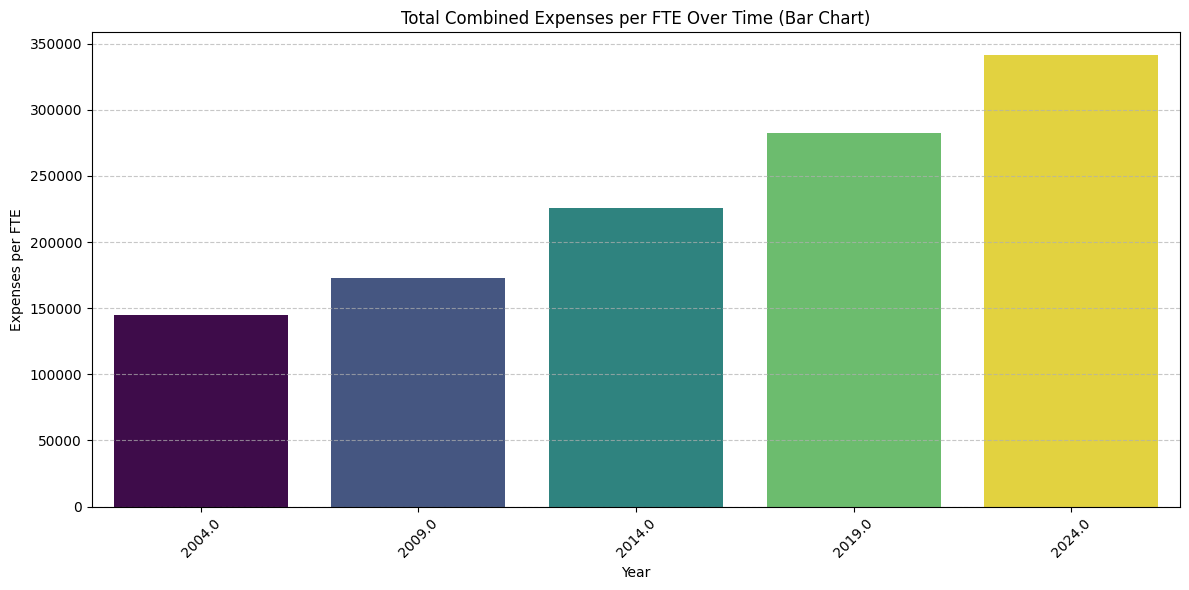

In [ ]:
# Calculate 'Expenses per FTE' in the yearly_expenses_fte DataFrame
yearly_expenses_fte['Expenses_per_FTE'] = yearly_expenses_fte['Total_Combined_Expenses'] / yearly_expenses_fte['HOSP_FTE']

print("Yearly Expenses, FTEs, and Expenses per FTE:")
display(yearly_expenses_fte)

# Plot 'Expenses_per_FTE' over time
plt.figure(figsize=(12, 6))
sns.lineplot(x='YEAR', y='Expenses_per_FTE', data=yearly_expenses_fte, marker='o')
plt.title('Total Combined Expenses per FTE Over Time')
plt.xlabel('Year')
plt.ylabel('Expenses per FTE')
plt.grid(True)
plt.xticks(yearly_expenses_fte['YEAR'])
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(x='YEAR', y='Expenses_per_FTE', data=yearly_expenses_fte, hue='YEAR', palette='viridis', legend=False)
plt.title('Total Combined Expenses per FTE Over Time (Bar Chart)')
plt.xlabel('Year')
plt.ylabel('Expenses per FTE')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
merged_with_end_year.head()

,FAC_NO,FAC_NAME,BEG_DATE,END_DATE,DAY_PER,DATA_IND,AUDIT_IND,COUNTY,HSA,HFPA,...,PD_HR_ADM,PD_HR_NON,NAT_0BIRTHS,BEG_YEAR,YEAR,Patient_Expenses,Overhead_Expenses,Total_Combined_Expenses,Other_FTE,AVG_WAGE
0,106010846,ALAMEDA COUNTY MEDICAL CENTER,2003-07-01,2004-06-30,366.0,AUDITED,EXCL. IND. AUDIT,ALAMEDA,5.0,417.0,...,482813.0,NaN,NaN,2003.0,2004.0,163621843.0,160311636.0,323933479.0,1494.0,63535.089945
1,106010735,ALAMEDA HOSPITAL,2003-07-01,2004-06-30,366.0,AUDITED,INCL. IND. AUDIT,ALAMEDA,5.0,417.0,...,107765.0,NaN,NaN,2003.0,2004.0,30851410.0,21390163.0,52241573.0,264.0,55760.801047
2,106190017,ALHAMBRA HOSPITAL - ALHAMBRA,2003-07-01,2004-06-30,366.0,AUDITED,EXCL. IND. AUDIT,LOS ANGELES,11.0,913.0,...,101170.0,NaN,NaN,2003.0,2004.0,31497779.0,18946409.0,50444188.0,251.0,43284.715618
3,106010739,ALTA BATES SUMMIT MED CTR-ALTA BATES CAM,2004-01-01,2004-12-31,366.0,AUDITED,INCL. IND. AUDIT,ALAMEDA,5.0,415.0,...,388515.0,NaN,NaN,2004.0,2004.0,277537023.0,157565571.0,435102594.0,1372.0,65350.854995
4,106010937,ALTA BATES SUMMIT MED CTR-SUMMIT-HAWTHOR,2004-01-01,2004-12-31,366.0,AUDITED,INCL. IND. AUDIT,ALAMEDA,5.0,417.0,...,231959.0,NaN,NaN,2004.0,2004.0,202291344.0,124064482.0,326355826.0,1042.0,73369.559099


In [ ]:
#merged_with_end_year.to_csv(folder / "Merged_CY_Extracts_2004_2024.csv", index=False)
#print(f"Merged data saved to: {folder / "Merged_CY_Extracts_2004_2024.csv"}")

In [ ]:
'''
csv_file_path = folder / "Merged_CY_Extracts_2004_2024.csv"
excel_file_path = folder / "Merged_CY_Extracts_2004_2024.xlsx"

# Read the CSV file into a DataFrame
df_to_excel = pd.read_csv(csv_file_path)

# Save the DataFrame to an Excel file
df_to_excel.to_excel(excel_file_path, index=False)

print(f"CSV file '{csv_file_path.name}' successfully converted and saved as Excel: {excel_file_path}")
'''

'\ncsv_file_path = folder / "Merged_CY_Extracts_2004_2024.csv"\nexcel_file_path = folder / "Merged_CY_Extracts_2004_2024.xlsx"\n\n# Read the CSV file into a DataFrame\ndf_to_excel = pd.read_csv(csv_file_path)\n\n# Save the DataFrame to an Excel file\ndf_to_excel.to_excel(excel_file_path, index=False)\n\nprint(f"CSV file \'{csv_file_path.name}\' successfully converted and saved as Excel: {excel_file_path}")\n'

###March 30th

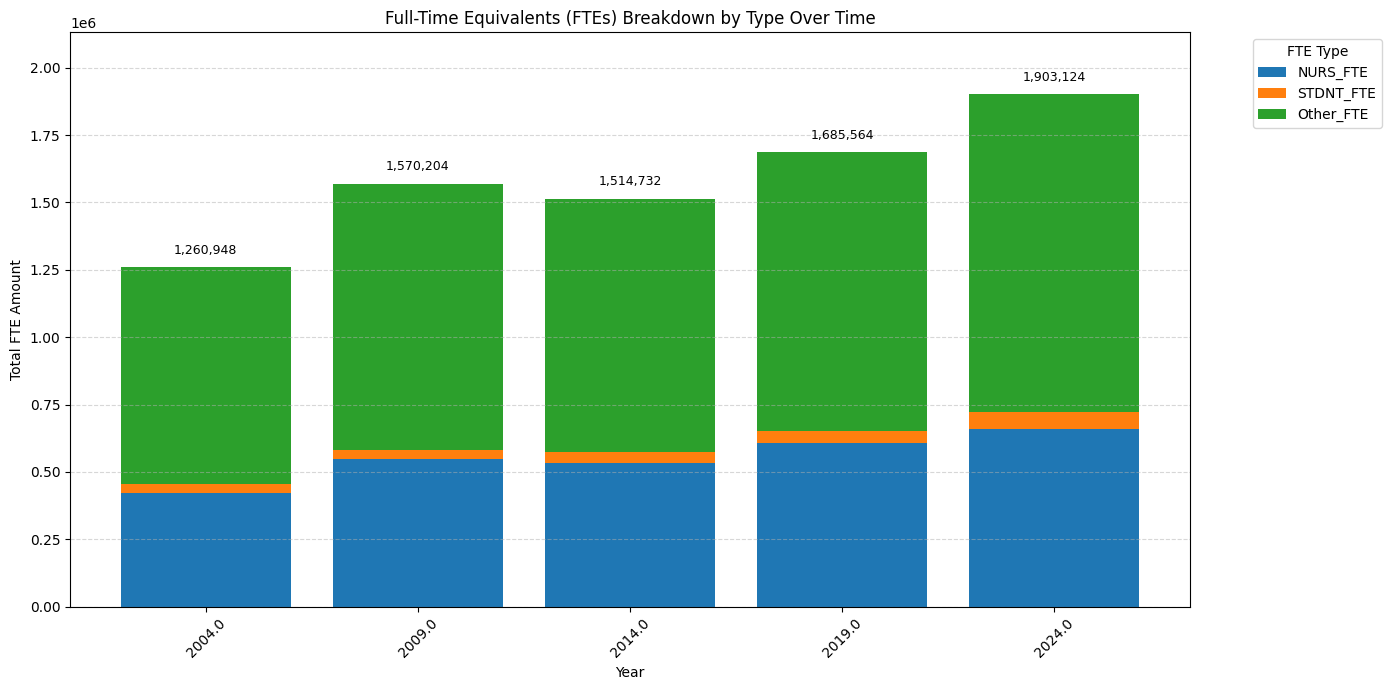

In [ ]:
fte_cols = ['Other_FTE', 'NURS_FTE', 'STDNT_FTE']

# Group by year
fte_breakdown = (
    merged_with_end_year
    .groupby('YEAR')[fte_cols]
    .sum()
    .reset_index()
    .sort_values('YEAR')
)

years = fte_breakdown['YEAR'].astype(str).tolist()
x = np.arange(len(years))

# Use a numpy array for stacking
bottom = np.zeros(len(fte_breakdown))

fig, ax = plt.subplots(figsize=(14, 7))

# Plot in the desired order: NURS_FTE (bottom), STDNT_FTE, HOSP_FTE (top)
plotting_order = ['NURS_FTE', 'STDNT_FTE', 'Other_FTE']

for col in plotting_order:
    ax.bar(x, fte_breakdown[col].values, bottom=bottom, label=col)
    bottom += fte_breakdown[col].values

# Total labels on top
yearly_total_ftes = fte_breakdown[fte_cols].sum(axis=1).values
offset = yearly_total_ftes.max() * 0.02

for i, total in enumerate(yearly_total_ftes):
    ax.text(
        x[i],
        total + offset,
        f'{total:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9,
        color='black'
    )

ax.set_title('Full-Time Equivalents (FTEs) Breakdown by Type Over Time')
ax.set_xlabel('Year')
ax.set_ylabel('Total FTE Amount')
ax.set_xticks(x)
ax.set_xticklabels(years, rotation=45)
ax.legend(title='FTE Type', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.set_ylim(0, yearly_total_ftes.max() * 1.12)

plt.tight_layout()
plt.show()

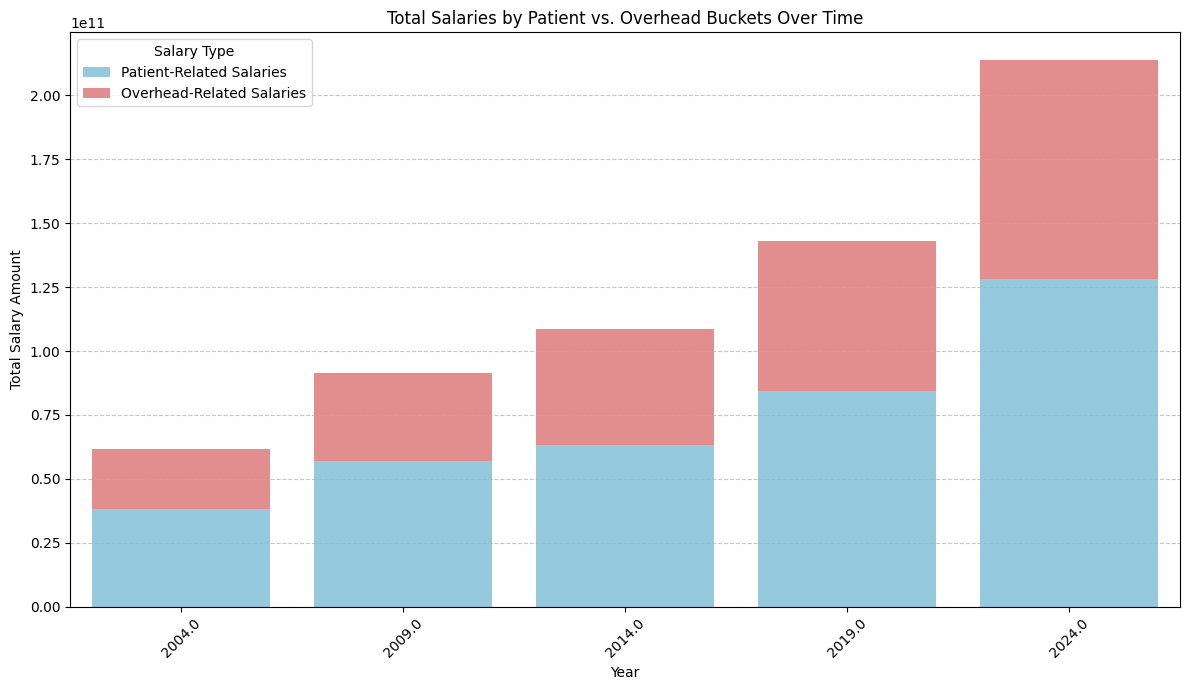

Yearly Salaries by Patient vs. Overhead Buckets:


,YEAR,Salary_Patient_Bucket,Salary_Overhead_Bucket
0,2004.0,3.817928e+10,2.356048e+10
1,2009.0,5.682978e+10,3.462641e+10
2,2014.0,6.343031e+10,4.531054e+10
3,2019.0,8.432525e+10,5.889684e+10
4,2024.0,1.282038e+11,8.579442e+10


In [ ]:
# Calculate proportional salaries for patient and overhead buckets
# Handle cases where Total_Combined_Expenses might be zero to avoid division errors
total_expenses_mask = merged_with_end_year['Total_Combined_Expenses'] != 0

merged_with_end_year.loc[total_expenses_mask, 'Salary_Patient_Bucket'] = \
    merged_with_end_year['EXP_SAL'] * (merged_with_end_year['Patient_Expenses'] / merged_with_end_year['Total_Combined_Expenses'])

merged_with_end_year.loc[total_expenses_mask, 'Salary_Overhead_Bucket'] = \
    merged_with_end_year['EXP_SAL'] * (merged_with_end_year['Overhead_Expenses'] / merged_with_end_year['Total_Combined_Expenses'])

# For records where Total_Combined_Expenses is zero, set salary buckets to 0
merged_with_end_year.loc[~total_expenses_mask, 'Salary_Patient_Bucket'] = 0
merged_with_end_year.loc[~total_expenses_mask, 'Salary_Overhead_Bucket'] = 0

# Group by YEAR and sum the new salary buckets
yearly_salary_buckets = merged_with_end_year.groupby('YEAR')[['Salary_Patient_Bucket', 'Salary_Overhead_Bucket']].sum().reset_index()

# Plotting
plt.figure(figsize=(12, 7))

# Create a stacked bar chart
sns.barplot(x='YEAR', y='Salary_Patient_Bucket', data=yearly_salary_buckets, color='skyblue', label='Patient-Related Salaries')
sns.barplot(x='YEAR', y='Salary_Overhead_Bucket', data=yearly_salary_buckets, color='lightcoral', bottom=yearly_salary_buckets['Salary_Patient_Bucket'], label='Overhead-Related Salaries')

plt.title('Total Salaries by Patient vs. Overhead Buckets Over Time')
plt.xlabel('Year')
plt.ylabel('Total Salary Amount')
plt.legend(title='Salary Type')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Display the yearly sums
print("Yearly Salaries by Patient vs. Overhead Buckets:")
display(yearly_salary_buckets)

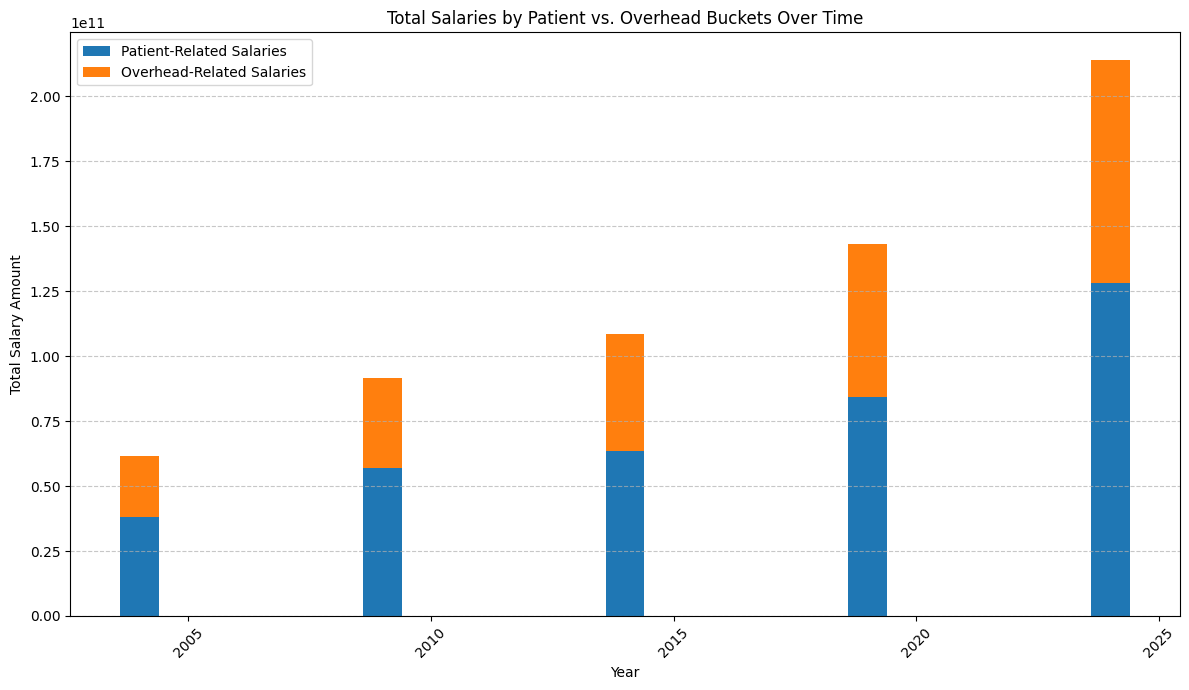

In [ ]:
# Group by YEAR
yearly_salary_buckets = (
    merged_with_end_year
    .groupby('YEAR')[['Salary_Patient_Bucket', 'Salary_Overhead_Bucket']]
    .sum()
    .reset_index()
)

# Plot stacked bars
plt.figure(figsize=(12, 7))
plt.bar(
    yearly_salary_buckets['YEAR'],
    yearly_salary_buckets['Salary_Patient_Bucket'],
    label='Patient-Related Salaries'
)
plt.bar(
    yearly_salary_buckets['YEAR'],
    yearly_salary_buckets['Salary_Overhead_Bucket'],
    bottom=yearly_salary_buckets['Salary_Patient_Bucket'],
    label='Overhead-Related Salaries'
)

plt.title('Total Salaries by Patient vs. Overhead Buckets Over Time')
plt.xlabel('Year')
plt.ylabel('Total Salary Amount')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
cols = [
    'DAY_TOT',
    'DIS_TOT',
    'DIS_NURSRY',
    'VIS_TOT',
    'VIS_ER',
    'VIS_CLIN',
    'VIS_REF_OP',
    'OP_MIN_IP',
    'OP_MIN_OP',
    'SURG_IP',
    'SURG_OP',
    'NAT_0BIRTHS',
    'C_SECTIONS'
]

yearly_totals = (
    merged_with_end_year
    .groupby('YEAR')[cols]
    .sum()
    .reset_index()
)

display(yearly_totals)

,YEAR,DAY_TOT,DIS_TOT,DIS_NURSRY,VIS_TOT,VIS_ER,VIS_CLIN,VIS_REF_OP,OP_MIN_IP,OP_MIN_OP,SURG_IP,SURG_OP,NAT_0BIRTHS,C_SECTIONS
0,2004.0,56895831.0,8963769.0,1057917.0,114674283.0,24797004.0,37053183.0,44152740.0,380380062.0,265558062.0,2697981.0,3617562.0,0.0,337446.0
1,2009.0,56952588.0,9329850.0,1092207.0,126100479.0,31711776.0,39708921.0,46577328.0,375087258.0,265285719.0,2620530.0,3429285.0,0.0,442899.0
2,2014.0,53716434.0,8957160.0,862698.0,129509229.0,36686013.0,42980442.0,42626358.0,363700383.0,286977003.0,2365614.0,3431034.0,0.0,428733.0
3,2019.0,56195226.0,9187416.0,708111.0,143441064.0,40552794.0,55837530.0,42287577.0,353341254.0,326368770.0,2312259.0,3871584.0,0.0,353154.0
4,2024.0,58500528.0,8989302.0,589884.0,163311510.0,42223659.0,62469447.0,53473191.0,350762631.0,380404224.0,2068671.0,4176864.0,709611.0,326421.0


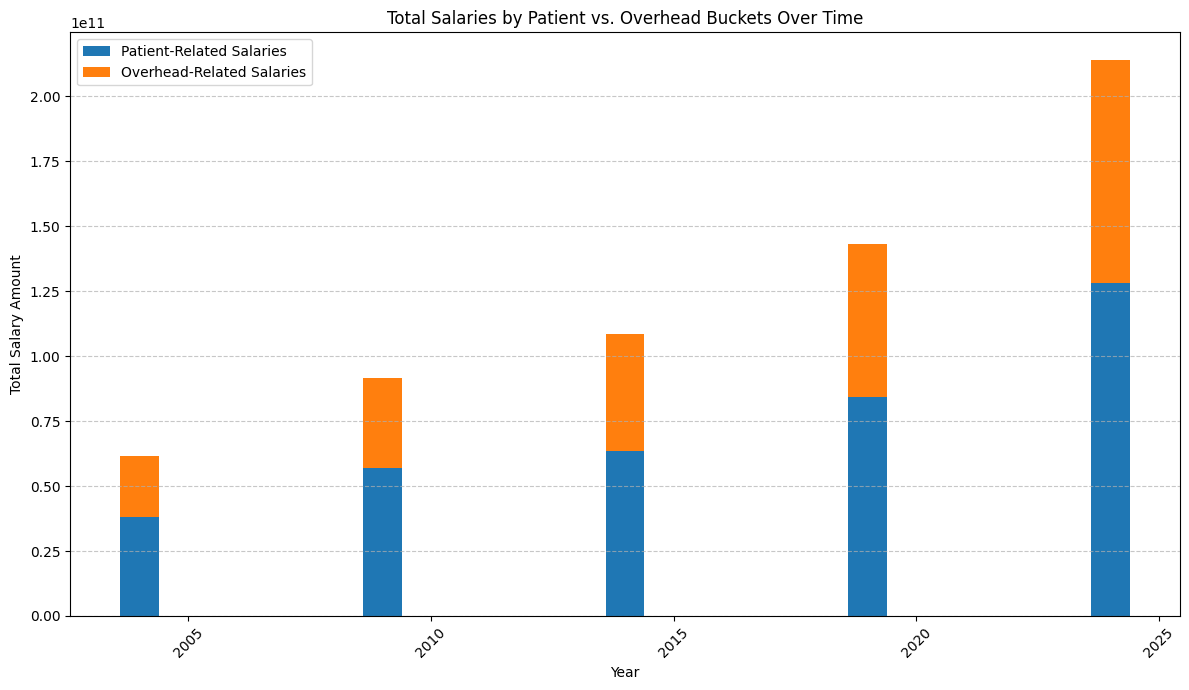

In [ ]:
# Group by YEAR
yearly_salary_buckets = (
    merged_with_end_year
    .groupby('YEAR')[['Salary_Patient_Bucket', 'Salary_Overhead_Bucket']]
    .sum()
    .reset_index()
)

# Plot stacked bars
plt.figure(figsize=(12, 7))
plt.bar(
    yearly_salary_buckets['YEAR'],
    yearly_salary_buckets['Salary_Patient_Bucket'],
    label='Patient-Related Salaries'
)
plt.bar(
    yearly_salary_buckets['YEAR'],
    yearly_salary_buckets['Salary_Overhead_Bucket'],
    bottom=yearly_salary_buckets['Salary_Patient_Bucket'],
    label='Overhead-Related Salaries'
)

plt.title('Total Salaries by Patient vs. Overhead Buckets Over Time')
plt.xlabel('Year')
plt.ylabel('Total Salary Amount')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
yearly_salary_buckets['Total'] = (
    yearly_salary_buckets['Salary_Patient_Bucket'] +
    yearly_salary_buckets['Salary_Overhead_Bucket']
)

yearly_salary_buckets['Patient_%'] = (
    yearly_salary_buckets['Salary_Patient_Bucket'] /
    yearly_salary_buckets['Total']
)

yearly_salary_buckets['Overhead_%'] = (
    yearly_salary_buckets['Salary_Overhead_Bucket'] /
    yearly_salary_buckets['Total']
)

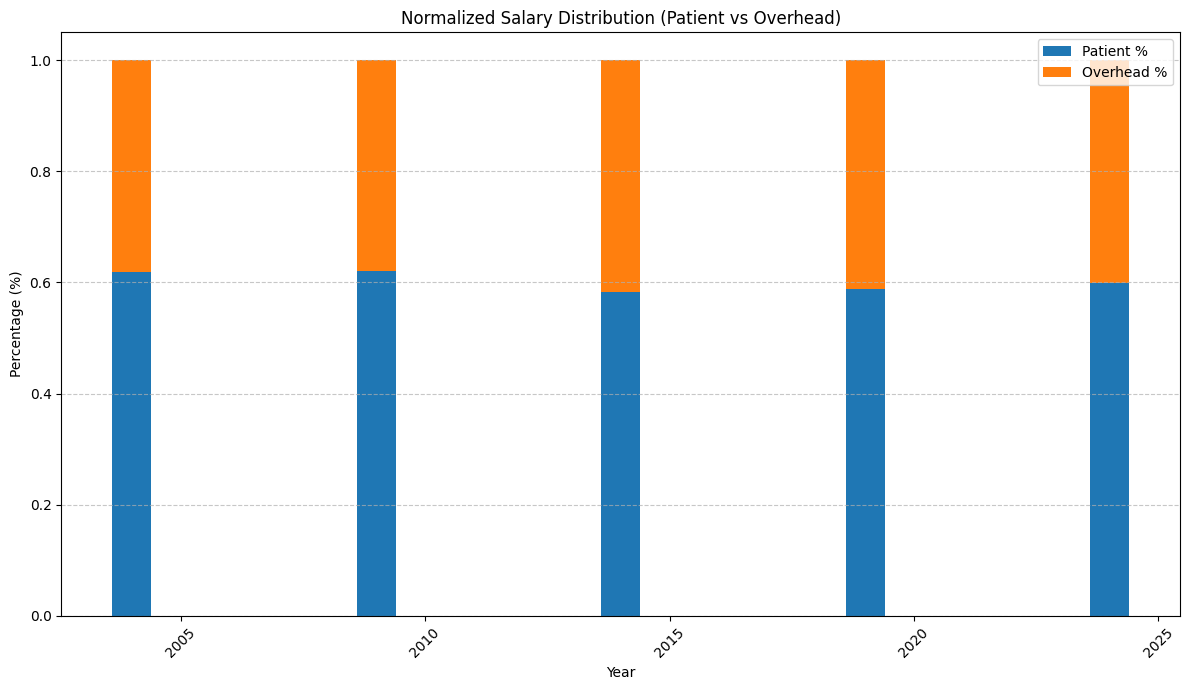

In [ ]:
plt.figure(figsize=(12, 7))

plt.bar(
    yearly_salary_buckets['YEAR'],
    yearly_salary_buckets['Patient_%'],
    label='Patient %'
)

plt.bar(
    yearly_salary_buckets['YEAR'],
    yearly_salary_buckets['Overhead_%'],
    bottom=yearly_salary_buckets['Patient_%'],
    label='Overhead %'
)

plt.title('Normalized Salary Distribution (Patient vs Overhead)')
plt.xlabel('Year')
plt.ylabel('Percentage (%)')
yearly_salary_buckets['Patient_%'] *= 100
yearly_salary_buckets['Overhead_%'] *= 100
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



In [ ]:
cols = [
    'DAY_TOT',
    'DIS_TOT',
    'DIS_NURSRY',
    'VIS_TOT',
    'VIS_ER',
    'VIS_CLIN',
    'VIS_REF_OP',
    'OP_MIN_IP',
    'OP_MIN_OP',
    'SURG_IP',
    'SURG_OP',
    'NAT_0BIRTHS',
    'C_SECTIONS'
]

hospital_totals = (
    merged_with_end_year
    .groupby(['FAC_NO', 'FAC_NAME'])[cols]
    .sum()
    .reset_index()
)

display(hospital_totals)

,FAC_NO,FAC_NAME,DAY_TOT,DIS_TOT,DIS_NURSRY,VIS_TOT,VIS_ER,VIS_CLIN,VIS_REF_OP,OP_MIN_IP,OP_MIN_OP,SURG_IP,SURG_OP,NAT_0BIRTHS,C_SECTIONS
0,106010735,ALAMEDA HOSPITAL,1618572.0,89502.0,0.0,2122410.0,571224.0,934494.0,660480.0,2277894.0,3922710.0,18504.0,76008.0,0.0,0.0
1,106010739,ALTA BATES SUMMIT MED CTR-ALTA BATES CAM,878622.0,160128.0,46818.0,1531788.0,250488.0,182100.0,671838.0,6013404.0,5854956.0,44382.0,55416.0,0.0,12972.0
2,106010739,ALTA BATES SUMMIT MED CTR-ALTA BATES CAMPUS,772842.0,134742.0,40824.0,2063562.0,262758.0,189384.0,675060.0,2494440.0,1834560.0,20496.0,25722.0,0.0,12672.0
3,106010739,ALTA BATES SUMMIT MEDICAL CENTER - ALTA BATES ...,1426332.0,265104.0,78312.0,2968230.0,757140.0,1063974.0,877518.0,4675200.0,5710890.0,35796.0,71262.0,16482.0,25068.0
4,106010776,CHILDREN'S HOSPITAL AND RESEARCH CENTER AT OAK...,300678.0,62292.0,0.0,1418070.0,275022.0,1065510.0,105096.0,2594160.0,1832040.0,20982.0,30192.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
650,106560529,ST. JOHN'S REGIONAL MEDICAL CENTER,1962042.0,364710.0,50790.0,3333234.0,1712268.0,413214.0,1280304.0,12520440.0,10375212.0,87438.0,115290.0,5910.0,16758.0
651,106571086,WOODLAND MEMORIAL HOSPITAL,563592.0,130752.0,0.0,2808078.0,743454.0,0.0,1187946.0,4075878.0,9529140.0,51840.0,239916.0,1962.0,5508.0
652,106574010,SUTTER DAVIS HOSPITAL,301566.0,106272.0,35568.0,1881762.0,805542.0,389850.0,638424.0,2691864.0,7163238.0,23754.0,99162.0,6684.0,6942.0
653,106580996,ADVENTIST HEALTH AND RIDEOUT,823830.0,174354.0,23970.0,3827298.0,1054284.0,1905264.0,1020486.0,3938892.0,4034868.0,35286.0,43488.0,7920.0,8280.0


In [ ]:
merged_with_end_year['Patient_Expenses'] = merged_with_end_year[patient_expense_cols].sum(axis=1)
merged_with_end_year['Overhead_Expenses'] = merged_with_end_year[overhead_expense_cols].sum(axis=1)

hospital_costs = (
    merged_with_end_year
    .groupby(['FAC_NO', 'FAC_NAME'])[['Patient_Expenses', 'Overhead_Expenses']]
    .sum()
    .reset_index()
)

In [ ]:
hospital_analysis = hospital_totals.merge(
    hospital_costs,
    on=['FAC_NO', 'FAC_NAME']
)

In [ ]:
hospital_analysis['Cost_per_Discharge'] = (
    (hospital_analysis['Patient_Expenses'] + hospital_analysis['Overhead_Expenses']) /
    hospital_analysis['DIS_TOT']
)

hospital_analysis['Patient_Cost_per_Discharge'] = (
    hospital_analysis['Patient_Expenses'] /
    hospital_analysis['DIS_TOT']
)

hospital_analysis['Overhead_per_Discharge'] = (
    hospital_analysis['Overhead_Expenses'] /
    hospital_analysis['DIS_TOT']
)

hospital_analysis['Overhead_%'] = (
    hospital_analysis['Overhead_Expenses'] /
    (hospital_analysis['Patient_Expenses'] + hospital_analysis['Overhead_Expenses'])
)

In [ ]:
hospital_analysis.sort_values(by='Overhead_%', ascending=False).head(10)

,FAC_NO,FAC_NAME,DAY_TOT,DIS_TOT,DIS_NURSRY,VIS_TOT,VIS_ER,VIS_CLIN,VIS_REF_OP,OP_MIN_IP,...,SURG_IP,SURG_OP,NAT_0BIRTHS,C_SECTIONS,Patient_Expenses,Overhead_Expenses,Cost_per_Discharge,Patient_Cost_per_Discharge,Overhead_per_Discharge,Overhead_%
546,106410806,KAISER FDN HOSP - SOUTH SAN FRANCISCO,164454.0,38718.0,0.0,20904.0,0.0,0.0,0.0,1820340.0,...,13806.0,20904.0,0.0,0.0,90419984.0,323518380.0,10691.109148,2335.347487,8355.761661,0.781562
212,106190552,MOTION PICTURE AND TELEVISION HOSPITAL,1187682.0,3240.0,0.0,374178.0,0.0,368808.0,0.0,0.0,...,0.0,5370.0,0.0,0.0,220150452.0,552642904.0,238516.467901,67947.670370,170568.797531,0.715124
636,106560203,AURORA VISTA DEL MAR HOSPITAL,552708.0,79596.0,0.0,80172.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,121342500.0,246403664.0,4620.158852,1524.479873,3095.678979,0.670037
393,106330120,THE BETTY FORD CENTER,313578.0,18978.0,0.0,195912.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,94562148.0,175511556.0,14230.883339,4982.724629,9248.158710,0.649865
186,106190434,KAISER FDN HOSP - WEST LA,271116.0,67974.0,5940.0,33636.0,0.0,0.0,0.0,2067666.0,...,13152.0,33636.0,0.0,0.0,210225772.0,373013704.0,8580.331833,3092.737988,5487.593845,0.639555
130,106190163,AURORA CHARTER OAK,1242918.0,173010.0,0.0,339300.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,238584676.0,415151272.0,3778.602092,1379.022461,2399.579631,0.635044
482,106370730,KAISER FDN HOSP - SAN DIEGO,630222.0,161394.0,17406.0,117396.0,0.0,0.0,0.0,6506622.0,...,43410.0,117396.0,0.0,0.0,410963844.0,700559204.0,6887.015924,2546.339046,4340.676878,0.630270
392,106330120,BETTY FORD CENTER OF EISENHOWER,537696.0,23052.0,0.0,383568.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,185255176.0,310365556.0,21500.118515,8036.403609,13463.714905,0.626216
497,106374024,AURORA SAN DIEGO,793458.0,83688.0,0.0,354996.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,176479732.0,293876916.0,5620.359526,2108.781809,3511.577717,0.624796
340,106301155,COLLEGE HOSPITAL COSTA MESA,1145766.0,125724.0,0.0,473388.0,0.0,0.0,55560.0,45540.0,...,366.0,1398.0,0.0,0.0,438521888.0,708064772.0,9119.870987,3487.972766,5631.898222,0.617541


In [ ]:
hospital_analysis.sort_values(by='Cost_per_Discharge', ascending=False).head(10)

,FAC_NO,FAC_NAME,DAY_TOT,DIS_TOT,DIS_NURSRY,VIS_TOT,VIS_ER,VIS_CLIN,VIS_REF_OP,OP_MIN_IP,...,SURG_IP,SURG_OP,NAT_0BIRTHS,C_SECTIONS,Patient_Expenses,Overhead_Expenses,Cost_per_Discharge,Patient_Cost_per_Discharge,Overhead_per_Discharge,Overhead_%
576,106434051,CHILDRENS RECOVERY CTR OF NO CALIF,42288.0,42.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.469804e+07,6.189408e+06,497320.095238,349953.238095,147366.857143,0.296322
575,106434051,CHILDRENS RECOVERY CENTER OF NORTHERN CALIFORNIA,99684.0,144.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,4.272176e+07,1.814573e+07,422690.861111,296678.861111,126012.000000,0.298119
574,106434051,CHILDREN'S HEALTHCARE ORGANIZATION OF NORTHERN...,112350.0,270.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,5.920184e+07,3.893913e+07,363485.081481,219266.074074,144219.007407,0.396767
116,106190045,CATALINA ISLAND MEDICAL CENTER,52626.0,546.0,0.0,461910.0,47130.0,154110.0,248766.0,0.0,...,0.0,0.0,0.0,0.0,8.887082e+07,8.166147e+07,312330.190476,162767.062271,149563.128205,0.478862
212,106190552,MOTION PICTURE AND TELEVISION HOSPITAL,1187682.0,3240.0,0.0,374178.0,0.0,368808.0,0.0,0.0,...,0.0,5370.0,0.0,0.0,2.201505e+08,5.526429e+08,238516.467901,67947.670370,170568.797531,0.715124
504,106380842,HEBREW HOME FOR THE AGED DISABLED,921432.0,822.0,0.0,0.0,0.0,44238.0,0.0,0.0,...,0.0,0.0,0.0,0.0,9.227449e+07,8.441483e+07,214950.510949,112256.068127,102694.442822,0.477759
512,106380865,LAGUNA HONDA HOSPITAL AND REHABILITATION CENTER,4332744.0,19752.0,0.0,102768.0,0.0,101346.0,1446.0,0.0,...,0.0,0.0,0.0,0.0,1.849586e+09,1.454171e+09,167261.925678,93640.447752,73621.477926,0.440157
510,106380865,LAGUNA HONDA HOSP & REHAB CENTER,1786068.0,5340.0,0.0,74610.0,0.0,21042.0,0.0,0.0,...,0.0,0.0,0.0,0.0,4.385995e+08,2.769395e+08,133996.070412,82134.737079,51861.333333,0.387036
133,106190176,CITY OF HOPE HELFORD CLINICAL RESEARCH HOSPITAL,1613214.0,166932.0,0.0,5684400.0,0.0,4855776.0,976908.0,14878254.0,...,71454.0,138432.0,0.0,0.0,1.179984e+10,9.167774e+09,125605.728297,70686.514126,54919.214171,0.437235
568,106430905,STANFORD HEALTH CARE,2458212.0,378828.0,0.0,23628804.0,1148706.0,12695706.0,12039876.0,40914978.0,...,178866.0,441066.0,0.0,0.0,2.929074e+10,1.627296e+10,120275.434677,77319.366161,42956.068517,0.357147


In [ ]:
hospital_analysis.sort_values(by='Cost_per_Discharge').head(10)

,FAC_NO,FAC_NAME,DAY_TOT,DIS_TOT,DIS_NURSRY,VIS_TOT,VIS_ER,VIS_CLIN,VIS_REF_OP,OP_MIN_IP,...,SURG_IP,SURG_OP,NAT_0BIRTHS,C_SECTIONS,Patient_Expenses,Overhead_Expenses,Cost_per_Discharge,Patient_Cost_per_Discharge,Overhead_per_Discharge,Overhead_%
30,106044006,BUTTE COUNTY MENTAL HEALTH - PHF,139752.0,18210.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
624,106514001,SUTTER-YUBA - PHF,44718.0,5808.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
623,106514001,SUTTER - YUBA - PHF,50766.0,5754.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
560,106424002,SANTA BARBARA PSYCHIATRIC HEALTH FACILITY,96072.0,6504.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
79,106124004,SEMPERVIRENS P.H.F.,59802.0,5106.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
54,106094002,EL DORADO COUNTY MENTAL HEALTH-PHF,16008.0,2244.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
53,106094002,EL DORADO COUNTY MENTAL HEALTH - PHF,39762.0,4692.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
80,106124004,SEMPERVIRENS PSYCHIATRIC HEALTH FACILITY,23148.0,3612.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
531,106394003,SAN JOAQUIN COUNTY MENTAL HEALTH - PHF,81654.0,8742.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
532,106394003,SAN JOAQUIN COUNTY MENTAL HEALTH SERVICES,69396.0,7422.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN


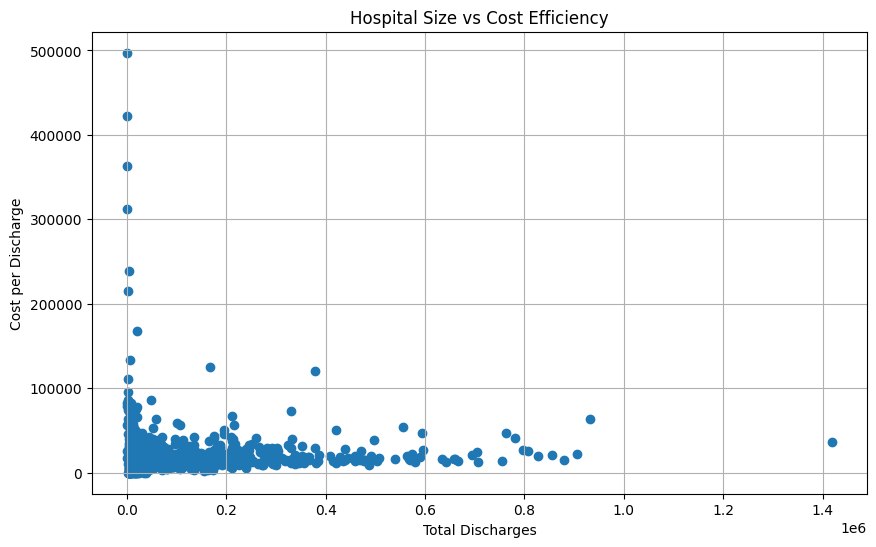

In [ ]:
plt.figure(figsize=(10,6))
plt.scatter(
    hospital_analysis['DIS_TOT'],
    hospital_analysis['Cost_per_Discharge']
)
plt.xlabel('Total Discharges')
plt.ylabel('Cost per Discharge')
plt.title('Hospital Size vs Cost Efficiency')
plt.grid(True)
plt.show()

In [ ]:
hospital_year_totals = (
    merged_with_end_year
    .groupby(['FAC_NO', 'FAC_NAME', 'YEAR'])[cols]
    .sum()
    .reset_index()
)

display(hospital_year_totals)

,FAC_NO,FAC_NAME,YEAR,DAY_TOT,DIS_TOT,DIS_NURSRY,VIS_TOT,VIS_ER,VIS_CLIN,VIS_REF_OP,OP_MIN_IP,OP_MIN_OP,SURG_IP,SURG_OP,NAT_0BIRTHS,C_SECTIONS
0,106010735,ALAMEDA HOSPITAL,2004.0,63762.0,9114.0,0.0,128340.0,52047.0,0.0,83016.0,473013.0,417012.0,3285.0,6999.0,0.0,0.0
1,106010735,ALAMEDA HOSPITAL,2009.0,91386.0,8871.0,0.0,145116.0,52011.0,1575.0,89844.0,347070.0,767580.0,2070.0,15585.0,0.0,0.0
2,106010735,ALAMEDA HOSPITAL,2014.0,207702.0,8676.0,0.0,559971.0,50979.0,386886.0,135438.0,141558.0,126318.0,1743.0,4773.0,0.0,0.0
3,106010735,ALAMEDA HOSPITAL,2019.0,230061.0,8796.0,0.0,126222.0,73506.0,39315.0,11115.0,108960.0,339120.0,1362.0,5655.0,0.0,0.0
4,106010735,ALAMEDA HOSPITAL,2024.0,216375.0,9294.0,0.0,101556.0,57069.0,39471.0,10827.0,68346.0,311325.0,792.0,4992.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1790,106580996,ADVENTIST HEALTH AND RIDEOUT,2019.0,249537.0,53061.0,7671.0,1346283.0,307479.0,910632.0,198663.0,1277481.0,1242264.0,13167.0,13998.0,0.0,2460.0
1791,106580996,ADVENTIST HEALTH AND RIDEOUT,2024.0,162378.0,34116.0,4314.0,567366.0,219663.0,42000.0,311580.0,691965.0,775170.0,4476.0,7746.0,3960.0,1680.0
1792,106580996,RIDEOUT MEMORIAL HOSPITAL,2004.0,144063.0,33312.0,4065.0,403371.0,118404.0,0.0,283215.0,875253.0,640653.0,8643.0,8571.0,0.0,1893.0
1793,106580996,RIDEOUT MEMORIAL HOSPITAL,2009.0,176679.0,39864.0,6861.0,503889.0,161601.0,56751.0,325974.0,934635.0,1630800.0,8634.0,20514.0,0.0,1782.0


In [ ]:
hospital_year_costs = (
    merged_with_end_year
    .groupby(['FAC_NO', 'FAC_NAME', 'YEAR'])[['Patient_Expenses', 'Overhead_Expenses']]
    .sum()
    .reset_index()
)

hospital_year_analysis = hospital_year_totals.merge(
    hospital_year_costs,
    on=['FAC_NO', 'FAC_NAME', 'YEAR']
)

display(hospital_year_analysis.head())

,FAC_NO,FAC_NAME,YEAR,DAY_TOT,DIS_TOT,DIS_NURSRY,VIS_TOT,VIS_ER,VIS_CLIN,VIS_REF_OP,OP_MIN_IP,OP_MIN_OP,SURG_IP,SURG_OP,NAT_0BIRTHS,C_SECTIONS,Patient_Expenses,Overhead_Expenses
0,106010735,ALAMEDA HOSPITAL,2004.0,63762.0,9114.0,0.0,128340.0,52047.0,0.0,83016.0,473013.0,417012.0,3285.0,6999.0,0.0,0.0,123405640.0,85560652.0
1,106010735,ALAMEDA HOSPITAL,2009.0,91386.0,8871.0,0.0,145116.0,52011.0,1575.0,89844.0,347070.0,767580.0,2070.0,15585.0,0.0,0.0,183852400.0,91376536.0
2,106010735,ALAMEDA HOSPITAL,2014.0,207702.0,8676.0,0.0,559971.0,50979.0,386886.0,135438.0,141558.0,126318.0,1743.0,4773.0,0.0,0.0,241545952.0,128576652.0
3,106010735,ALAMEDA HOSPITAL,2019.0,230061.0,8796.0,0.0,126222.0,73506.0,39315.0,11115.0,108960.0,339120.0,1362.0,5655.0,0.0,0.0,330344772.0,168267828.0
4,106010735,ALAMEDA HOSPITAL,2024.0,216375.0,9294.0,0.0,101556.0,57069.0,39471.0,10827.0,68346.0,311325.0,792.0,4992.0,0.0,0.0,404852552.0,278991824.0


In [ ]:
'''
hospital_year_financials = (
    merged_with_end_year
    .groupby(['FAC_NO', 'FAC_NAME', 'YEAR'])[['Total_Combined_Expenses', 'AVG_WAGE', 'HOSP_FTE']]
    .agg(
        Total_Combined_Expenses=('Total_Combined_Expenses', 'sum'),
        AVG_WAGE=('AVG_WAGE', 'mean')  # Use mean for average wage
    )
    .reset_index()
)

hospital_year_analysis = hospital_year_analysis.merge(
    hospital_year_financials,
    on=['FAC_NO', 'FAC_NAME', 'YEAR'],
    how='left' # Use left merge to keep all original records
)

print("Updated hospital_year_analysis with Total_Combined_Expenses, AVG_WAGE, and Total_FTE:")
display(hospital_year_analysis.head())
'''

'\nhospital_year_financials = (\n    merged_with_end_year\n    .groupby([\'FAC_NO\', \'FAC_NAME\', \'YEAR\'])[[\'Total_Combined_Expenses\', \'AVG_WAGE\', \'HOSP_FTE\']]\n    .agg(\n        Total_Combined_Expenses=(\'Total_Combined_Expenses\', \'sum\'),\n        AVG_WAGE=(\'AVG_WAGE\', \'mean\')  # Use mean for average wage\n    )\n    .reset_index()\n)\n\nhospital_year_analysis = hospital_year_analysis.merge(\n    hospital_year_financials,\n    on=[\'FAC_NO\', \'FAC_NAME\', \'YEAR\'],\n    how=\'left\' # Use left merge to keep all original records\n)\n\nprint("Updated hospital_year_analysis with Total_Combined_Expenses, AVG_WAGE, and Total_FTE:")\ndisplay(hospital_year_analysis.head())\n'

In [ ]:
'''
columns_to_drop = [col for col in hospital_year_analysis.columns if col.endswith('_x') or col.endswith('_y')]

if columns_to_drop:
    print(f"Dropping columns: {columns_to_drop}")
    hospital_year_analysis = hospital_year_analysis.drop(columns=columns_to_drop)
    print("Columns dropped successfully.")
else:
    print("No columns with '_x' or '_y' suffixes found to drop.")

display(hospital_year_analysis.head())
'''

'\ncolumns_to_drop = [col for col in hospital_year_analysis.columns if col.endswith(\'_x\') or col.endswith(\'_y\')]\n\nif columns_to_drop:\n    print(f"Dropping columns: {columns_to_drop}")\n    hospital_year_analysis = hospital_year_analysis.drop(columns=columns_to_drop)\n    print("Columns dropped successfully.")\nelse:\n    print("No columns with \'_x\' or \'_y\' suffixes found to drop.")\n\ndisplay(hospital_year_analysis.head())\n'

In [ ]:
'''
csv_file_path = folder / "hospital_year_analysis.csv"
hospital_year_analysis.to_csv(csv_file_path, index=False)
print(f"DataFrame saved to: {csv_file_path}")
'''

'\ncsv_file_path = folder / "hospital_year_analysis.csv"\nhospital_year_analysis.to_csv(csv_file_path, index=False)\nprint(f"DataFrame saved to: {csv_file_path}")\n'

In [ ]:
'''
excel_file_path = folder / "hospital_year_analysis.xlsx"
hospital_year_analysis.to_excel(excel_file_path, index=False)
print(f"DataFrame successfully converted and saved as Excel: {excel_file_path}")
'''

'\nexcel_file_path = folder / "hospital_year_analysis.xlsx"\nhospital_year_analysis.to_excel(excel_file_path, index=False)\nprint(f"DataFrame successfully converted and saved as Excel: {excel_file_path}")\n'

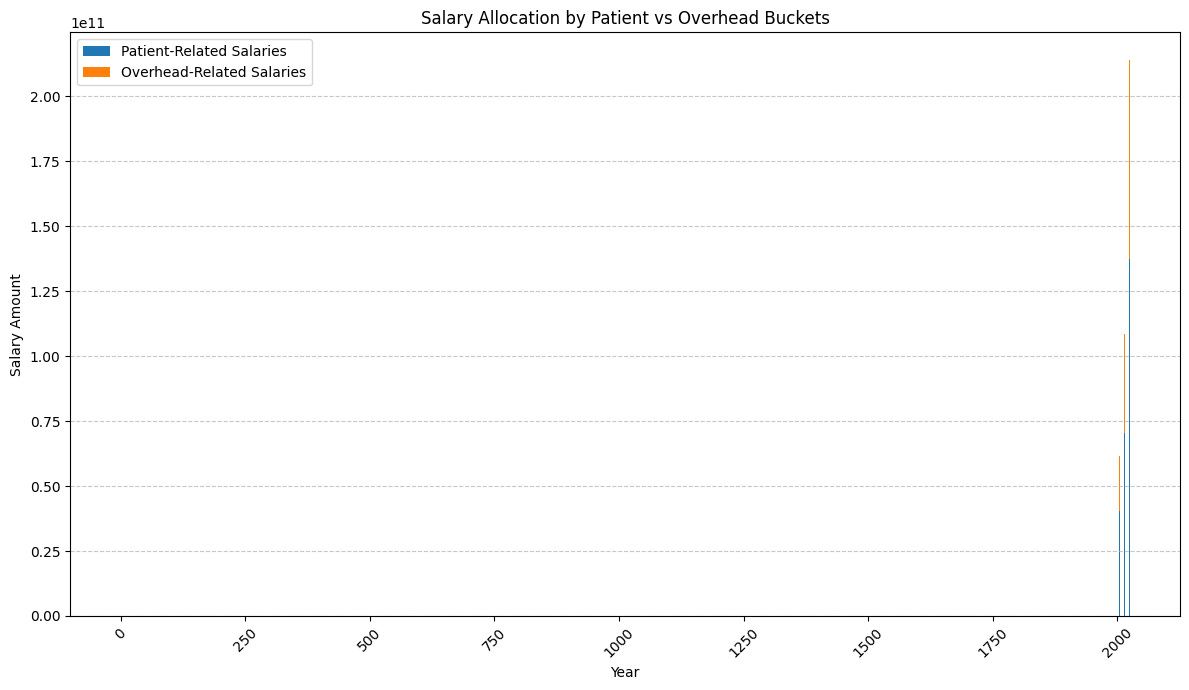

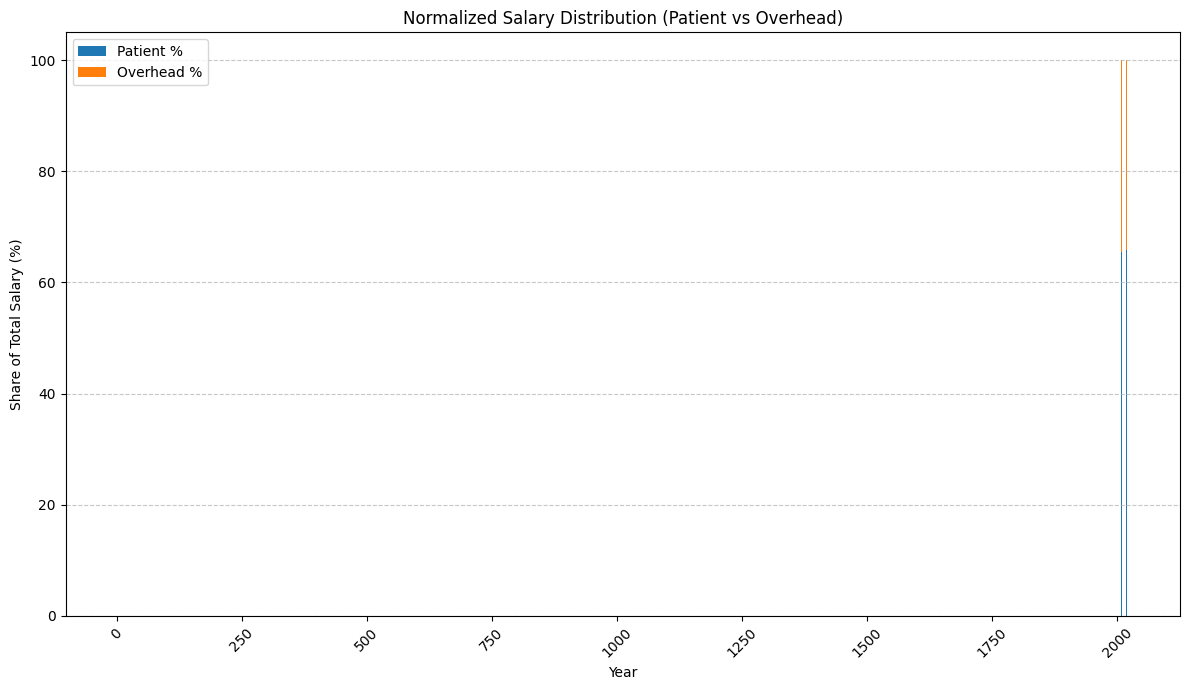

,YEAR,Salary_Patient_Bucket,Salary_Overhead_Bucket,Total_Salary,Patient_Pct,Overhead_Pct
0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000
1,2004.0,4.025345e+10,2.147445e+10,6.172790e+10,0.652111,0.347889
2,2009.0,5.979937e+10,3.164258e+10,9.144195e+10,0.653960,0.346040
3,2014.0,7.034404e+10,3.839681e+10,1.087408e+11,0.646896,0.353104
4,2019.0,9.423144e+10,4.899066e+10,1.432221e+11,0.657939,0.342061
5,2024.0,1.375251e+11,7.647312e+10,2.139982e+11,0.642646,0.357354


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# 1) Define hour buckets
# -----------------------------
patient_hour_cols = [
    'PRD_HR_DLY',
    'PRD_HR_AMB',
    'PRD_HR_ANC'
]

overhead_hour_cols = [
    'PRD_HR_ED',
    'PRD_HR_GEN',
    'PRD_HR_FIS',
    'PRD_HR_ADM',
    'PRD_HR_NON'
]

# -----------------------------
# 2) Make sure missing values do not break the math
# -----------------------------
for col in patient_hour_cols + overhead_hour_cols + ['EXP_SAL', 'YEAR']:
    merged_with_end_year[col] = merged_with_end_year[col].fillna(0)

# -----------------------------
# 3) Compute total hours by bucket
# -----------------------------
merged_with_end_year['Patient_Hours'] = merged_with_end_year[patient_hour_cols].sum(axis=1)
merged_with_end_year['Overhead_Hours'] = merged_with_end_year[overhead_hour_cols].sum(axis=1)
merged_with_end_year['Total_Hours'] = (
    merged_with_end_year['Patient_Hours'] + merged_with_end_year['Overhead_Hours']
)

# -----------------------------
# 4) Allocate salaries by hour share
# -----------------------------
merged_with_end_year['Salary_Patient_Bucket'] = np.where(
    merged_with_end_year['Total_Hours'] > 0,
    merged_with_end_year['EXP_SAL'] * (
        merged_with_end_year['Patient_Hours'] / merged_with_end_year['Total_Hours']
    ),
    0
)

merged_with_end_year['Salary_Overhead_Bucket'] = np.where(
    merged_with_end_year['Total_Hours'] > 0,
    merged_with_end_year['EXP_SAL'] * (
        merged_with_end_year['Overhead_Hours'] / merged_with_end_year['Total_Hours']
    ),
    0
)

# -----------------------------
# 5) Sum by year
# -----------------------------
yearly_salary_buckets = (
    merged_with_end_year
    .groupby('YEAR')[['Salary_Patient_Bucket', 'Salary_Overhead_Bucket']]
    .sum()
    .reset_index()
    .sort_values('YEAR')
)

# -----------------------------
# 6) Add normalized shares
# -----------------------------
yearly_salary_buckets['Total_Salary'] = (
    yearly_salary_buckets['Salary_Patient_Bucket'] +
    yearly_salary_buckets['Salary_Overhead_Bucket']
)

yearly_salary_buckets['Patient_Pct'] = np.where(
    yearly_salary_buckets['Total_Salary'] > 0,
    yearly_salary_buckets['Salary_Patient_Bucket'] / yearly_salary_buckets['Total_Salary'],
    0
)

yearly_salary_buckets['Overhead_Pct'] = np.where(
    yearly_salary_buckets['Total_Salary'] > 0,
    yearly_salary_buckets['Salary_Overhead_Bucket'] / yearly_salary_buckets['Total_Salary'],
    0
)

# -----------------------------
# 7) Plot raw dollars
# -----------------------------
plt.figure(figsize=(12, 7))

plt.bar(
    yearly_salary_buckets['YEAR'],
    yearly_salary_buckets['Salary_Patient_Bucket'],
    label='Patient-Related Salaries'
)

plt.bar(
    yearly_salary_buckets['YEAR'],
    yearly_salary_buckets['Salary_Overhead_Bucket'],
    bottom=yearly_salary_buckets['Salary_Patient_Bucket'],
    label='Overhead-Related Salaries'
)

plt.title('Salary Allocation by Patient vs Overhead Buckets')
plt.xlabel('Year')
plt.ylabel('Salary Amount')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# -----------------------------
# 8) Plot normalized shares
# -----------------------------
plt.figure(figsize=(12, 7))

plt.bar(
    yearly_salary_buckets['YEAR'],
    yearly_salary_buckets['Patient_Pct'] * 100,
    label='Patient %'
)

plt.bar(
    yearly_salary_buckets['YEAR'],
    yearly_salary_buckets['Overhead_Pct'] * 100,
    bottom=yearly_salary_buckets['Patient_Pct'] * 100,
    label='Overhead %'
)

plt.title('Normalized Salary Distribution (Patient vs Overhead)')
plt.xlabel('Year')
plt.ylabel('Share of Total Salary (%)')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(yearly_salary_buckets)

In [ ]:
print("Displaying yearly salary buckets data:")
display(yearly_salary_buckets)

Displaying yearly salary buckets data:


,YEAR,Salary_Patient_Bucket,Salary_Overhead_Bucket,Total_Salary,Patient_Pct,Overhead_Pct
0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000
1,2004.0,4.025345e+10,2.147445e+10,6.172790e+10,0.652111,0.347889
2,2009.0,5.979937e+10,3.164258e+10,9.144195e+10,0.653960,0.346040
3,2014.0,7.034404e+10,3.839681e+10,1.087408e+11,0.646896,0.353104
4,2019.0,9.423144e+10,4.899066e+10,1.432221e+11,0.657939,0.342061
5,2024.0,1.375251e+11,7.647312e+10,2.139982e+11,0.642646,0.357354


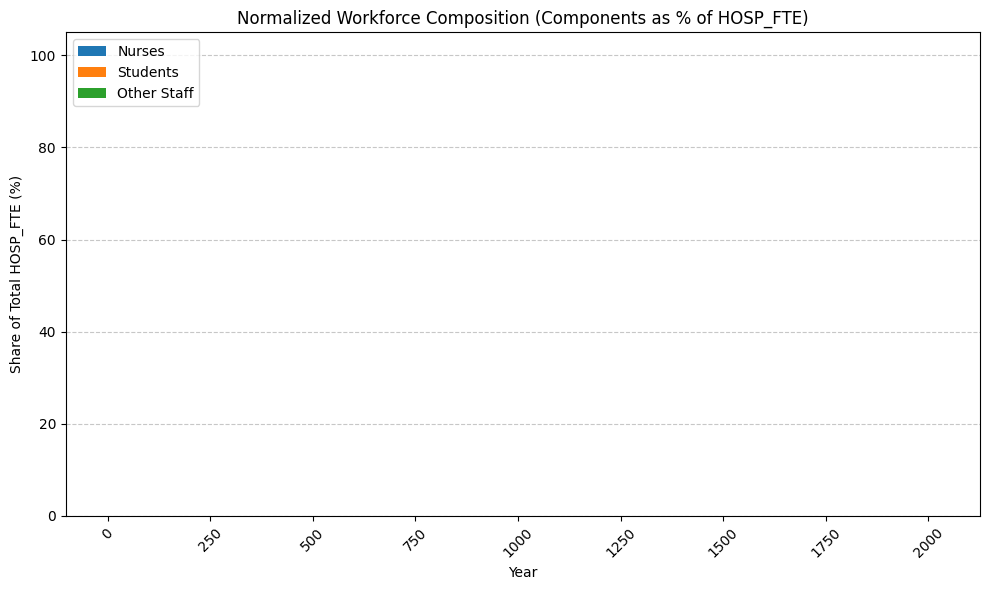

,YEAR,HOSP_FTE,NURS_FTE,STDNT_FTE,Other_FTE,NURS_%,STDNT_%,OTHER_%
0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000
1,2004.0,1260948.0,422996.0,31272.0,806680.0,0.335459,0.024800,0.639741
2,2009.0,1570204.0,546488.0,33564.0,990152.0,0.348036,0.021376,0.630588
3,2014.0,1514732.0,532464.0,40672.0,941596.0,0.351524,0.026851,0.621625
4,2019.0,1685564.0,606056.0,46900.0,1032608.0,0.359557,0.027825,0.612619
5,2024.0,1903124.0,659500.0,63488.0,1180136.0,0.346535,0.033360,0.620105


In [ ]:
# -----------------------------
# 1) Aggregate by year
# -----------------------------
# Ensure 'Other_FTE' is available from previous calculations in merged_with_end_year
# and include it in the breakdown for plotting.
fte_cols_for_breakdown = ['HOSP_FTE', 'NURS_FTE', 'STDNT_FTE', 'Other_FTE']

fte_breakdown = (
    merged_with_end_year
    .groupby('YEAR')[fte_cols_for_breakdown]
    .sum()
    .reset_index()
)

# -----------------------------
# 2) Define total FTE as HOSP_FTE (as per user's latest definition)
# -----------------------------
fte_breakdown['TOTAL_FTE_FOR_NORMALIZATION'] = fte_breakdown['HOSP_FTE']

# -----------------------------
# 3) Normalize to percentages based on HOSP_FTE
# -----------------------------
# Handle division by zero for normalization
fte_breakdown['NURS_%'] = np.where(
    fte_breakdown['TOTAL_FTE_FOR_NORMALIZATION'] > 0,
    fte_breakdown['NURS_FTE'] / fte_breakdown['TOTAL_FTE_FOR_NORMALIZATION'],
    0
)
fte_breakdown['STDNT_%'] = np.where(
    fte_breakdown['TOTAL_FTE_FOR_NORMALIZATION'] > 0,
    fte_breakdown['STDNT_FTE'] / fte_breakdown['TOTAL_FTE_FOR_NORMALIZATION'],
    0
)
fte_breakdown['OTHER_%'] = np.where(
    fte_breakdown['TOTAL_FTE_FOR_NORMALIZATION'] > 0,
    fte_breakdown['Other_FTE'] / fte_breakdown['TOTAL_FTE_FOR_NORMALIZATION'],
    0
)

# -----------------------------
# 4) Plot normalized stacked bar chart
# -----------------------------
plt.figure(figsize=(10, 6))

# Stack 'Other_FTE', 'NURS_FTE', 'STDNT_FTE' to compose 100% of HOSP_FTE
plt.bar(
    fte_breakdown['YEAR'],
    fte_breakdown['NURS_%'] * 100,
    label='Nurses'
)

plt.bar(
    fte_breakdown['YEAR'],
    fte_breakdown['STDNT_%'] * 100,
    bottom=fte_breakdown['NURS_%'] * 100,
    label='Students'
)

plt.bar(
    fte_breakdown['YEAR'],
    fte_breakdown['OTHER_%'] * 100,
    bottom=(fte_breakdown['NURS_%'] + fte_breakdown['STDNT_%']) * 100,
    label='Other Staff'
)

plt.title('Normalized Workforce Composition (Components as % of HOSP_FTE)')
plt.xlabel('Year')
plt.ylabel('Share of Total HOSP_FTE (%)')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# -----------------------------
# 5) Display table
# -----------------------------
display(fte_breakdown[['YEAR', 'HOSP_FTE', 'NURS_FTE', 'STDNT_FTE', 'Other_FTE', 'NURS_%', 'STDNT_%', 'OTHER_%']])

In [ ]:
hospital_overall_totals = (
    hospital_year_analysis
    .groupby(['FAC_NO', 'FAC_NAME'])
    .agg(
        DAY_TOT=('DAY_TOT', 'sum'),
        DIS_TOT=('DIS_TOT', 'sum'),
        DIS_NURSRY=('DIS_NURSRY', 'sum'),
        VIS_TOT=('VIS_TOT', 'sum'),
        VIS_ER=('VIS_ER', 'sum'),
        VIS_CLIN=('VIS_CLIN', 'sum'),
        VIS_REF_OP=('VIS_REF_OP', 'sum'),
        OP_MIN_IP=('OP_MIN_IP', 'sum'),
        OP_MIN_OP=('OP_MIN_OP', 'sum'),
        SURG_IP=('SURG_IP', 'sum'),
        SURG_OP=('SURG_OP', 'sum'),
        NAT_0BIRTHS=('NAT_0BIRTHS', 'sum'),
        C_SECTIONS=('C_SECTIONS', 'sum'),
        Patient_Expenses=('Patient_Expenses', 'sum'),
        Overhead_Expenses=('Overhead_Expenses', 'sum'),
        Total_Combined_Expenses=('Total_Combined_Expenses', 'sum'),
        AVG_WAGE=('AVG_WAGE', 'mean'), # Using mean for average wage across years per hospital
        Total_FTE=('Total_FTE', 'sum')
    )
    .reset_index()
)

print("Overall totals for each hospital across all years:")
display(hospital_overall_totals.head())

KeyError: "Column(s) ['AVG_WAGE', 'Total_Combined_Expenses', 'Total_FTE'] do not exist"

In [ ]:
excel_file_path = folder / "hospital_overall_totals.xlsx"
hospital_overall_totals.to_excel(excel_file_path, index=False)
print(f"DataFrame 'hospital_overall_totals' successfully saved as Excel: {excel_file_path}")

In [ ]:
yearly_volume = (
    merged_with_end_year
    .groupby('YEAR')['DIS_TOT']
    .sum()
    .reset_index()
)

In [ ]:
yearly_volume = (
    merged_with_end_year
    .groupby('YEAR')['DIS_TOT']
    .sum()
    .reset_index()
)

plt.figure(figsize=(10, 6))

plt.bar(
    yearly_volume['YEAR'],
    yearly_volume['DIS_TOT']
)

plt.title('Total Hospital Discharges by Year')
plt.xlabel('Year')
plt.ylabel('Total Discharges')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Explicitly set x-ticks and labels
plt.xticks(yearly_volume['YEAR'], rotation=45)

# Ensure y-axis labels are not in scientific notation
plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# 1) Aggregate by year
# -----------------------------
yearly_data = (
    merged_with_end_year
    .groupby('YEAR')[[
        'DIS_TOT',
        'EXP_DLY','EXP_AMB','EXP_ANC','EXP_PIP','EXP_POP',
        'EXP_RES','EXP_ED','EXP_GEN','EXP_FISC','EXP_ADM','EXP_UNASSG'
    ]]
    .sum()
    .reset_index()
    .sort_values('YEAR')
)

# -----------------------------
# 2) Compute total expenses
# -----------------------------
expense_cols = [
    'EXP_DLY','EXP_AMB','EXP_ANC','EXP_PIP','EXP_POP',
    'EXP_RES','EXP_ED','EXP_GEN','EXP_FISC','EXP_ADM','EXP_UNASSG'
]

yearly_data['Total_Expenses'] = yearly_data[expense_cols].sum(axis=1)

# -----------------------------
# 3) Compute cost per discharge
# -----------------------------
yearly_data['Cost_per_Discharge'] = np.where(
    yearly_data['DIS_TOT'] > 0,
    yearly_data['Total_Expenses'] / yearly_data['DIS_TOT'],
    0
)

# -----------------------------
# 4) Plot 1: Total discharges
# -----------------------------
plt.figure(figsize=(10, 5))

plt.bar(yearly_data['YEAR'], yearly_data['DIS_TOT'])

plt.title('Total Hospital Discharges (Volume)')
plt.xlabel('Year')
plt.ylabel('Discharges')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# -----------------------------
# 5) Plot 2: Cost per discharge
# -----------------------------
plt.figure(figsize=(10, 5))

plt.bar(yearly_data['YEAR'], yearly_data['Cost_per_Discharge'])

plt.title('Cost per Discharge')
plt.xlabel('Year')
plt.ylabel('Cost per Discharge')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# -----------------------------
# 6) Display data
# -----------------------------
display(yearly_data[['YEAR', 'DIS_TOT', 'Cost_per_Discharge']])